<div style="background: linear-gradient(135deg, #003366 0%, #0055a5 100%); border-radius: 12px; padding: 18px 26px; display: flex; align-items: center; gap: 24px; box-shadow: 0 4px 12px rgba(0,0,0,0.2);">
    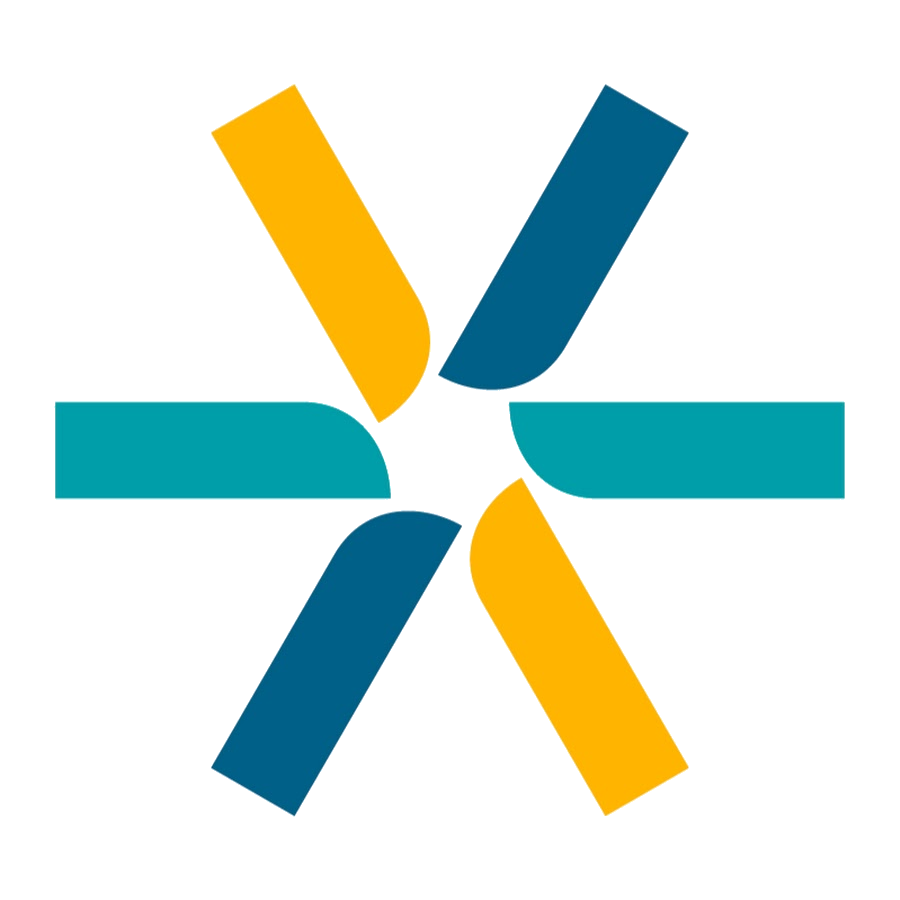
    <div>
        <h1 style="margin: 0; color: #ffffff; font-size: 1.45em; letter-spacing: 0.5px;">Aprendizaje Automático y Grandes Datos</h1>
        <h2 style="margin: 6px 0 2px 0; color: #cce4ff; font-size: 1.15em; font-weight: normal;">Regresión polinómica y regularización · demanda eléctrica (CAMMESA)</h2>
        <h3 style="margin: 0 0 8px 0; color: #a8d0f5; font-size: 1em; font-weight: normal;">Unidad 6 · Modelos lineales de regresión</h3>
        <span style="background: #ffd700; color: #003366; font-weight: bold; font-size: 0.9em; padding: 3px 12px; border-radius: 20px;">⚡ Grupo 6 · Clase 31 sobre nuestro dataset</span>
    </div>
</div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Antes de empezar</b></div><table style="border-collapse: collapse; width: 100%; font-size: 0.96em; margin-top: 4px;"><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">La pregunta</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">La misma del cuaderno anterior: ¿cuántos MWh va a demandar un agente (agente + tarifa) en un mes? La recta llegó a un RMSE de ~9 800 MWh, apenas mejor que copiar el mes anterior (~10 500). Dos preguntas nuevas: ¿hay algo que la recta no puede captar porque solo <b>suma</b>, y cómo se <b>frena</b> un modelo con muchas columnas para que no se descontrole?</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Los datos</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">El mismo <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">demanda-ltimos-aos.csv</code>, con las mismas seis predictoras construidas en la clase 29 (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1</code>, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag2</code>, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag12</code>, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">mes_num</code>, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">es_gran_usuario</code>, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">es_residencial</code>) y <b>una nueva</b>, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">ratio_dias</code>, que se justifica en la sección 1.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo que se quiere resolver</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Darle a la recta potencias y productos de las columnas; elegir el grado con validación; y frenar el sobreajuste bajando el grado, penalizando los pesos (Ridge, Lasso, Elastic Net) y parando a tiempo.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo que se muestra</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Las mismas 8 secciones de la clase 31: lo que la recta no captó → dejarlo listo → la polinómica → cómo se elige el grado → los frenos → comparativo → usarlo → qué quedó.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Cómo se decide</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Sobre el conjunto de prueba (2019-07 a 2020-02), en MWh, contra la media, contra copiar el mes anterior y contra la recta. Los hiperparámetros (grado, α) se eligen con validación cruzada temporal (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">TimeSeriesSplit</code>) sobre el entrenamiento, nunca mirando la prueba.</td></tr></table></div>

<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Qué cambia respecto del gimnasio</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">En el ejemplo de la cátedra el objetivo estaba <b>construido</b> como antigüedad × sesiones por mes: se sabía de antemano que el grado 2 tenía el término exacto y por eso ganaba con claridad. Con datos reales no se sabe qué término falta, ni si existe. Lo que sí se traslada es el método, y es lo que se aplica acá.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Adelanto honesto de lo que va a pasar: la polinómica <b>sin freno</b> no mejora a la recta, y los grados altos explotan. Lo que gana es la polinómica de grado 2 <b>con regularización</b>. Con estos datos, el freno no es un detalle: es lo que hace que el modelo funcione.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">1 · Lo que la recta no captó</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Los datos, con las predictoras de la clase 29</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Misma carga y mismos rezagos que en el cuaderno anterior (rutas relativas, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">utf-8-sig</code>, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">indice_tiempo</code> como texto).</p></div>

In [2]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

AZUL, AMBAR, GRIS, ROJO, VERDE = "#0055a5", "#f0a800", "#6b7280", "#c0392b", "#2e8b57"
pd.set_option("display.width", 120)
np.set_printoptions(suppress=True, precision=2)
warnings.filterwarnings("ignore", message="Skipping features without any observed values")   # primeros pliegues temporales sin lag12

CANDIDATAS = [Path("datos/demanda-ltimos-aos.csv"), Path("demanda-ltimos-aos.csv"), Path("../datos/demanda-ltimos-aos.csv")]
RUTA = next((p for p in CANDIDATAS if p.exists()), None)
if RUTA is None:
    raise FileNotFoundError(f"No encontré el CSV. Ponelo en alguna de estas rutas: {[str(p) for p in CANDIDATAS]}")
demanda = pd.read_csv(RUTA, encoding="utf-8-sig", dtype={"indice_tiempo": str})

demanda["periodo"] = pd.PeriodIndex(demanda["indice_tiempo"], freq="M")
demanda["serie"] = demanda["agente_nemo"] + " | " + demanda["tarifa"]
base_lags = demanda[["serie", "periodo", "demanda_MWh"]]
def rezago(k):
    t = base_lags.copy(); t["periodo"] = t["periodo"] + k
    return t.rename(columns={"demanda_MWh": f"lag{k}"})
for k in [1, 2, 12]:
    demanda = demanda.merge(rezago(k), on=["serie", "periodo"], how="left")
demanda["mes_num"] = demanda["periodo"].dt.month
demanda["es_gran_usuario"] = (demanda["categoria_demanda"] == "Gran Usuario").astype(int)
demanda["es_residencial"] = (demanda["categoria_tarifa"] == "Residencial").astype(int)

PREDICTORAS_29 = ["lag1", "lag2", "lag12", "mes_num", "es_gran_usuario", "es_residencial"]   # las de la clase 29
OBJETIVO = "demanda_MWh"
datos = demanda[demanda["lag1"].notna()].sort_values(["periodo", "serie"]).reset_index(drop=True)

CORTE = pd.Period("2019-06", freq="M")                       # el mismo corte temporal de la clase 29
ent_mask = datos["periodo"] <= CORTE
print(f"{len(datos)} filas · entrenamiento hasta {CORTE}: {ent_mask.sum()} · prueba: {(~ent_mask).sum()}")
datos[PREDICTORAS_29 + [OBJETIVO]].describe().round(1)

38077 filas · entrenamiento hasta 2019-06: 31962 · prueba: 6115


,lag1,lag2,lag12,mes_num,es_gran_usuario,es_residencial,demanda_MWh
count,38077.0,36285.0,21512.0,38077.0,38077.0,38077.0,38077.0
mean,10565.3,10660.0,11576.3,6.4,0.5,0.4,10586.7
std,46356.5,46271.7,45768.8,3.4,0.5,0.5,46618.8
min,-6554.3,-1757.1,-0.0,1.0,0.0,0.0,-6554.3
25%,319.9,344.8,547.4,3.0,0.0,0.0,317.8
50%,1277.7,1319.7,1580.9,6.0,0.0,0.0,1274.1
75%,4416.5,4501.9,5079.9,9.0,1.0,1.0,4405.1
max,1572308.1,1572308.1,1046149.6,12.0,1.0,1.0,1572308.1


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La recta de la clase 29, y qué dejó</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Se vuelve a ajustar la recta, solo para mirar sus residuos. La tercera figura es la pista: para cada mes del año, cuánto vale la demanda de este mes dividida la del mes anterior (la mediana entre agentes). Si la recta «copiar el mes pasado con una corrección» fuera suficiente, esa razón sería pareja.</p></div>

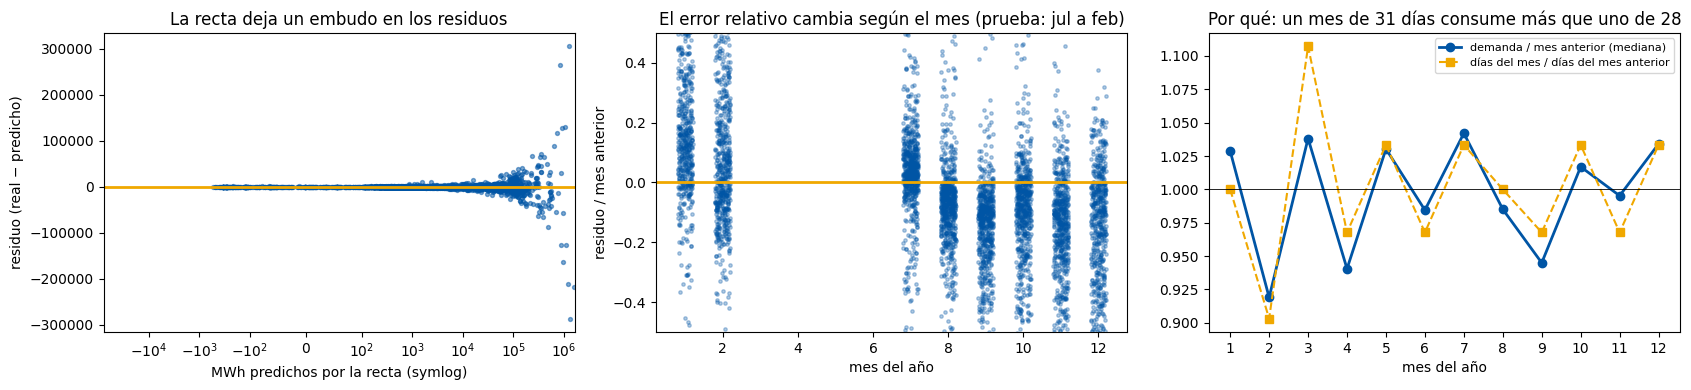

Recta (clase 29): RMSE sobre prueba = 9,825 MWh


In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

X_ent29, X_pru29 = datos.loc[ent_mask, PREDICTORAS_29], datos.loc[~ent_mask, PREDICTORAS_29]
y_ent, y_pru = datos.loc[ent_mask, OBJETIVO], datos.loc[~ent_mask, OBJETIVO]
recta = make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True), StandardScaler(), LinearRegression()).fit(X_ent29, y_ent)
pred_recta = recta.predict(X_pru29)
residuos_recta = y_pru - pred_recta

# La razón demanda / mes anterior, por mes del año (solo agentes con más de 1000 MWh, para que la razón sea estable)
grandes = datos[datos["lag1"] > 1000]
razon_mes = (grandes[OBJETIVO] / grandes["lag1"]).groupby(grandes["mes_num"]).median()
dias = pd.Series({m: pd.Period(f"2019-{m:02d}", "M").days_in_month for m in range(1, 13)})
razon_dias = dias / dias.shift(1, fill_value=dias[12])            # días del mes / días del mes anterior (enero / diciembre)

fig, (a, b, cc) = plt.subplots(1, 3, figsize=(17, 4))
a.scatter(pred_recta, residuos_recta, s=8, alpha=0.5, color=AZUL); a.axhline(0, color=AMBAR, lw=2); a.set_xscale("symlog", linthresh=100)
a.set_xlabel("MWh predichos por la recta (symlog)"); a.set_ylabel("residuo (real − predicho)"); a.set_title("La recta deja un embudo en los residuos")
b.scatter(X_pru29["mes_num"] + np.random.default_rng(2026).uniform(-0.2, 0.2, len(X_pru29)), residuos_recta / X_pru29["lag1"].abs().clip(lower=100), s=6, alpha=0.3, color=AZUL)
b.axhline(0, color=AMBAR, lw=2); b.set_ylim(-0.5, 0.5); b.set_xlabel("mes del año"); b.set_ylabel("residuo / mes anterior"); b.set_title("El error relativo cambia según el mes (prueba: jul a feb)")
cc.plot(razon_mes.index, razon_mes.values, marker="o", color=AZUL, lw=2, label="demanda / mes anterior (mediana)")
cc.plot(razon_dias.index, razon_dias.values, marker="s", color=AMBAR, lw=1.5, ls="--", label="días del mes / días del mes anterior")
cc.axhline(1, color="black", lw=0.6); cc.set_xticks(range(1, 13)); cc.set_xlabel("mes del año"); cc.legend(fontsize=8)
cc.set_title("Por qué: un mes de 31 días consume más que uno de 28")
plt.tight_layout(); plt.show()
print(f"Recta (clase 29): RMSE sobre prueba = {np.sqrt(np.mean(residuos_recta ** 2)):,.0f} MWh")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La figura de la derecha es el hallazgo de esta sección: la razón entre la demanda de un mes y la del anterior sube y baja en zigzag, y ese zigzag sigue de cerca a la <b>cantidad de días del mes</b>. Febrero (28 días) cae un 8 %; marzo (31) sube; abril (30) baja otra vez. Lo que se mide es energía acumulada en el mes, y un mes más largo acumula más.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Es el equivalente del «abanico» del gimnasio: la corrección que hay que aplicarle al mes anterior depende de otra cosa. Y esa corrección es un <b>producto</b>: demanda ≈ <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1</code> × (días del mes / días del mes anterior). Una recta no puede multiplicar. <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">mes_num</code> como número de 1 a 12 tampoco sirve: el zigzag no es una curva suave del mes.</p></div>

<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Una predictora nueva: ratio_dias</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Se agrega <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">ratio_dias</code> = días del mes / días del mes anterior. No es una elección a ojo: sale del gráfico de arriba y del significado físico de la variable (MWh acumulados en el mes). Por sí sola, en una recta, no alcanza, porque entra sumando. La polinómica de grado 2 sí la puede usar: entre sus productos está <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1 × ratio_dias</code>.</p></div>

In [4]:
def agregar_ratio_dias(df):
    """Días del mes / días del mes anterior (respeta los años bisiestos)."""
    return df["periodo"].dt.days_in_month / (df["periodo"] - 1).dt.days_in_month

datos["ratio_dias"] = agregar_ratio_dias(datos)
PREDICTORAS = PREDICTORAS_29 + ["ratio_dias"]
X = datos[PREDICTORAS]
X_ent, X_pru = X.loc[ent_mask], X.loc[~ent_mask]
print("ratio_dias por mes:", datos.groupby("mes_num")["ratio_dias"].first().round(3).to_dict())

ratio_dias por mes: {1: 1.0, 2: 0.903, 3: 1.107, 4: 0.968, 5: 1.033, 6: 0.968, 7: 1.033, 8: 1.0, 9: 0.968, 10: 1.033, 11: 0.968, 12: 1.033}


<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">2 · Dejarlo listo</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">El flujo de esta clase: imputar, expandir, escalar, modelo</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">PolynomialFeatures</code> va adentro del flujo, después de imputar y <b>antes</b> de escalar. Primero, qué hace con dos columnas y tres filas.</p></div>

In [5]:
from sklearn.preprocessing import PolynomialFeatures

ejemplo = pd.DataFrame({"lag1": [100, 200, 300], "ratio_dias": [1.0, 0.903, 1.107]})
expandido = PolynomialFeatures(degree=2, include_bias=False).fit(ejemplo)
pd.DataFrame(expandido.transform(ejemplo), columns=expandido.get_feature_names_out(["lag1", "ratio_dias"])).round(3)

,lag1,ratio_dias,lag1^2,lag1 ratio_dias,ratio_dias^2
0,100.0,1.000,10000.0,100.0,1.000
1,200.0,0.903,40000.0,180.6,0.815
2,300.0,1.107,90000.0,332.1,1.225


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La columna <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1 ratio_dias</code> es exactamente «el mes anterior corregido por días». Es la que se busca que el modelo aproveche.</p></div>

In [6]:
from sklearn.model_selection import TimeSeriesSplit

def flujo(grado, modelo):
    """Imputar, expandir a grado `grado`, escalar, y recién entonces el modelo."""
    return make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True),
                         PolynomialFeatures(degree=grado, include_bias=False),
                         StandardScaler(),
                         modelo)

def preparar(grado):
    return make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True), PolynomialFeatures(degree=grado, include_bias=False), StandardScaler())

CV = TimeSeriesSplit(n_splits=5)          # validación cruzada que respeta el orden temporal
for g in [1, 2, 3, 4, 5]:
    print(f"grado {g}: {PolynomialFeatures(degree=g, include_bias=False).fit(X_ent.fillna(0)).n_output_features_:4d} columnas a partir de 7")

grado 1:    7 columnas a partir de 7
grado 2:   35 columnas a partir de 7
grado 3:  119 columnas a partir de 7
grado 4:  329 columnas a partir de 7
grado 5:  791 columnas a partir de 7


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Las líneas de base, la recta, y el registro</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Como en la clase, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">registrar</code> guarda RMSE, MAE, R² y tiempo. Hay <b>cuatro</b> referencias: la media; copiar el mes anterior; copiar el mes anterior <b>corregido por días</b> (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1 × ratio_dias</code>, sin aprender nada); y la recta de la clase 29.</p></div>

In [7]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def rmse(y_real, y_pred):
    return np.sqrt(mean_squared_error(y_real, y_pred))

resultados = {}
def guardar(nombre, pred, t=0.0, modelo=None):
    resultados[nombre] = {"RMSE": rmse(y_pru, pred), "MAE": mean_absolute_error(y_pru, pred), "R²": r2_score(y_pru, pred), "ajuste (ms)": t, "modelo": modelo}

def registrar(nombre, modelo):
    t0 = time.perf_counter(); modelo.fit(X_ent, y_ent); t = (time.perf_counter() - t0) * 1000
    guardar(nombre, modelo.predict(X_pru), t, modelo)
    return modelo

registrar("línea de base (media)", DummyRegressor(strategy="mean"))
guardar("mes anterior", X_pru["lag1"])
guardar("mes anterior × ratio_dias", X_pru["lag1"] * X_pru["ratio_dias"])
guardar("recta clase 29 (6 predictoras)", pred_recta, modelo=recta)
registrar("recta (grado 1, 7 predictoras)", flujo(1, LinearRegression()))
pd.DataFrame({k: {m: v[m] for m in ["RMSE", "MAE", "R²"]} for k, v in resultados.items()}).round(3)

,línea de base (media),mes anterior,mes anterior × ratio_dias,recta clase 29 (6 predictoras),"recta (grado 1, 7 predictoras)"
RMSE,66698.567,10463.163,9343.388,9825.237,9811.051
MAE,17948.702,1544.941,1383.175,1605.180,1614.786
R²,-0.005,0.975,0.980,0.978,0.978


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Dos cosas. Primero, la corrección por días, <b>sin entrenar nada</b>, ya le gana a la recta de la clase 29: la idea de la sección 1 era correcta. Segundo, agregar <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">ratio_dias</code> a la recta casi no cambia nada, porque la recta suma y lo que hace falta es multiplicar. Esa es la vara para la polinómica.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">3 · El algoritmo</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La sentencia de la diapositiva</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">PolynomialFeatures(degree=2)</code> + <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">LinearRegression()</code>, tal cual, sobre los datos imputados. El modelo sigue siendo lineal en los pesos.</p></div>

In [8]:
imputador = SimpleImputer(strategy="median", keep_empty_features=True).fit(X_ent)
curva = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
curva.fit(imputador.transform(X_ent), y_ent)
print(f"Columnas que ve la recta: {curva[0].n_output_features_} (1 de sesgo + 7 lineales + 7 cuadrados + 21 productos)")
curva.predict(imputador.transform(X_pru.head()))

Columnas que ve la recta: 36 (1 de sesgo + 7 lineales + 7 cuadrados + 21 productos)


array([ 1185.91,  1169.05,   241.22,   359.95, 19598.52])

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué aprendió: 35 pesos</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con el flujo completo los coeficientes quedan en la misma unidad (MWh por desvío estándar de cada columna expandida). Los diez más grandes.</p></div>

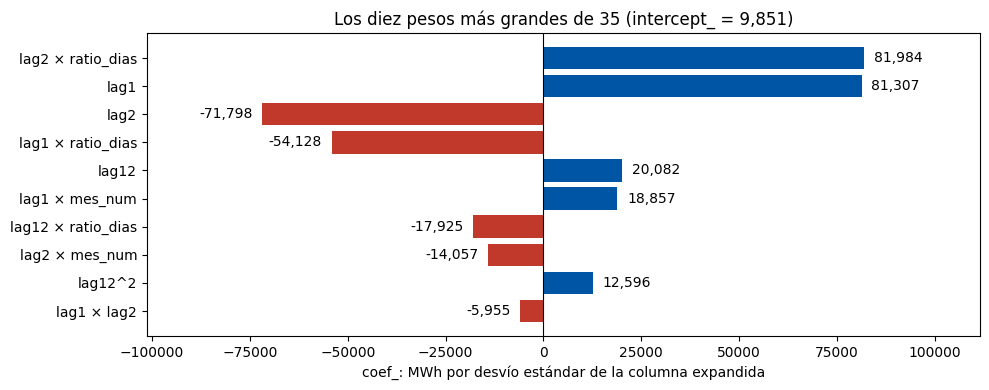

polinómica grado 2: RMSE prueba = 10,063   |   recta: 9,811


In [9]:
polinomica = registrar("polinómica grado 2", flujo(2, LinearRegression()))
def nombres(modelo):
    return [n.replace(" ", " × ") for n in modelo[1].get_feature_names_out(PREDICTORAS)]
coef2 = pd.Series(polinomica[-1].coef_, index=nombres(polinomica), name="coef_")
top = coef2.reindex(coef2.abs().sort_values(ascending=False).index)[:10]

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(top.index, top.values, color=[AZUL if v >= 0 else ROJO for v in top.values]); ax.invert_yaxis(); ax.axvline(0, color="black", lw=0.8)
m_ = 0.03 * top.abs().max()
for i, v in enumerate(top.values): ax.text(v + (m_ if v >= 0 else -m_), i, f"{v:,.0f}", va="center", ha="left" if v >= 0 else "right")
ax.set_xlim(top.min() - 12 * m_, top.max() + 12 * m_); ax.set_xlabel("coef_: MWh por desvío estándar de la columna expandida")
ax.set_title(f"Los diez pesos más grandes de 35 (intercept_ = {polinomica[-1].intercept_:,.0f})")
plt.tight_layout(); plt.show()
print(f"polinómica grado 2: RMSE prueba = {resultados['polinómica grado 2']['RMSE']:,.0f}   |   recta: {resultados['recta (grado 1, 7 predictoras)']['RMSE']:,.0f}")

<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Acá está la diferencia con el gimnasio. Allá un solo peso mandaba con claridad. Acá aparecen pesos enormes de signo opuesto que se cancelan entre sí: un rezago con +80 000 y otro con −70 000, el producto con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">ratio_dias</code> de uno positivo y el del otro negativo. Son columnas casi iguales (los rezagos estaban correlacionados en 0,98, y sus productos con lo mismo también), y sin freno la recta las usa para compensarse unas con otras.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Resultado: la polinómica sin freno <b>empeora</b> sobre prueba. No es que el producto no sirva; es que entre 35 columnas tan parecidas, la recta sin freno no tiene forma de elegir y sobreajusta. Es exactamente el problema que Ridge y Lasso vienen a resolver.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Uno, dos, veinte: la curva con una sola columna</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La figura de la diapositiva: la demanda contra <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1</code> con grado 1, 2 y 20.</p></div>

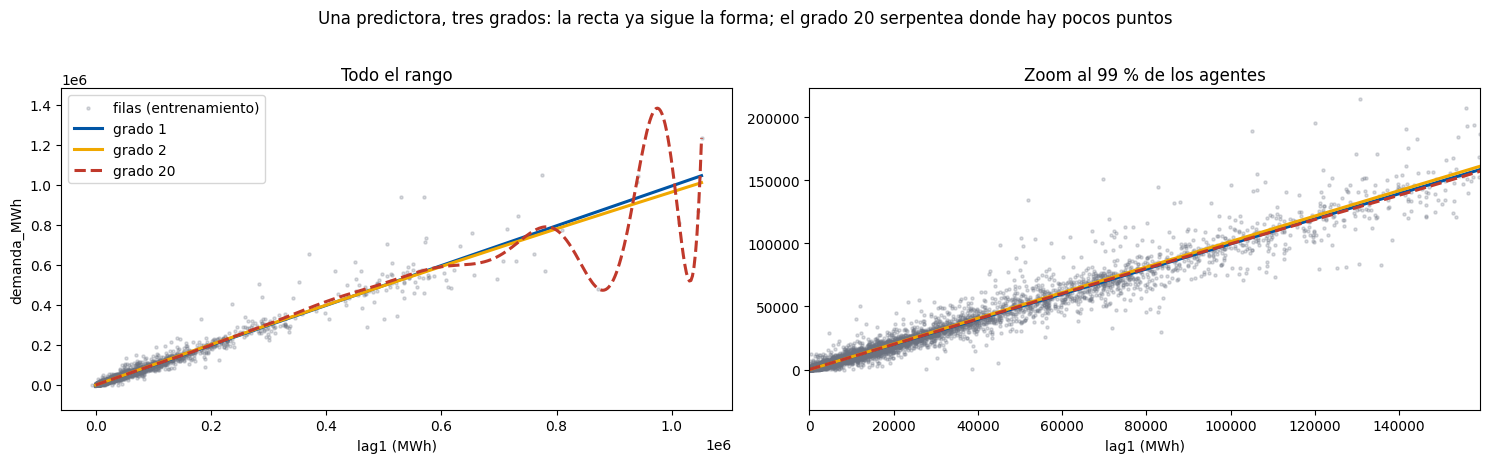

In [10]:
ent1 = datos.loc[ent_mask]
xs = pd.DataFrame({"lag1": np.linspace(0, ent1["lag1"].max(), 400)})
fig, (ax, zoom) = plt.subplots(1, 2, figsize=(15, 4.5))
for a in (ax, zoom):
    a.scatter(ent1["lag1"], ent1[OBJETIVO], s=5, alpha=0.25, color=GRIS, label="filas (entrenamiento)")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for grado, color, ls in [(1, AZUL, "-"), (2, AMBAR, "-"), (20, ROJO, "--")]:
        m = make_pipeline(PolynomialFeatures(degree=grado, include_bias=False), StandardScaler(), LinearRegression()).fit(ent1[["lag1"]], ent1[OBJETIVO])
        for a in (ax, zoom): a.plot(xs, m.predict(xs), color=color, lw=2.2, ls=ls, label=f"grado {grado}")
ax.set_ylim(-0.1 * ent1[OBJETIVO].max(), 1.2 * ent1[OBJETIVO].max()); ax.set_xlabel("lag1 (MWh)"); ax.set_ylabel(OBJETIVO); ax.legend(); ax.set_title("Todo el rango")
lim = ent1["lag1"].quantile(0.99)
zoom.set_xlim(0, lim); zoom.set_ylim(-0.2 * lim, 1.4 * lim); zoom.set_xlabel("lag1 (MWh)"); zoom.set_title("Zoom al 99 % de los agentes")
fig.suptitle("Una predictora, tres grados: la recta ya sigue la forma; el grado 20 serpentea donde hay pocos puntos", y=1.02)
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Al revés que en el gimnasio: contra el mes anterior la relación ya es casi una recta, y la parábola apenas se separa. El grado 20 serpentea y se dispara justo donde hay pocos puntos: entre los agentes gigantes, que son los que más pesan en el RMSE. Los grados altos van a ser peligrosos con estos datos.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Los residuos, antes y después</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Recta contra polinómica de grado 2 sin freno.</p></div>

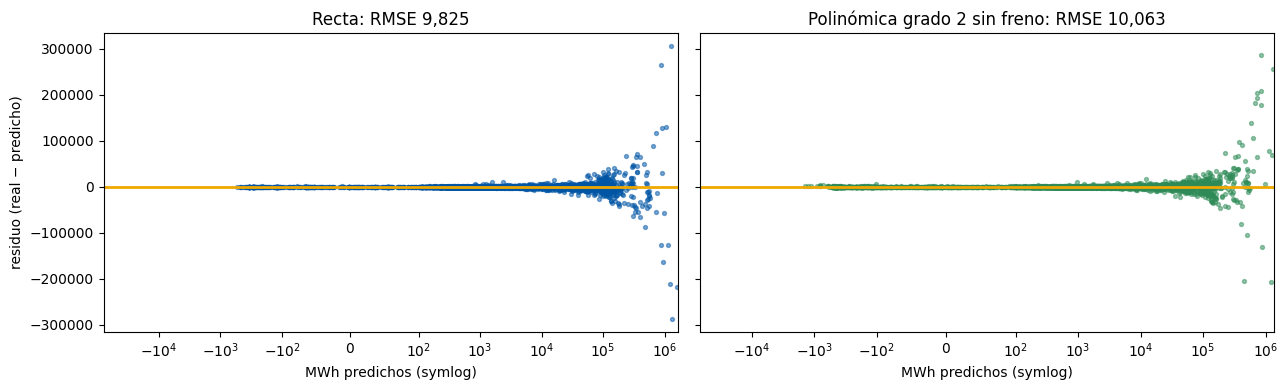

error absoluto mediano: recta 287 · grado 2 322 MWh


In [11]:
pred2 = polinomica.predict(X_pru)
residuos2 = y_pru - pred2
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
a.scatter(pred_recta, residuos_recta, s=8, alpha=0.5, color=AZUL); a.axhline(0, color=AMBAR, lw=2); a.set_xscale("symlog", linthresh=100)
a.set_title(f"Recta: RMSE {rmse(y_pru, pred_recta):,.0f}"); a.set_xlabel("MWh predichos (symlog)"); a.set_ylabel("residuo (real − predicho)")
b.scatter(pred2, residuos2, s=8, alpha=0.5, color=VERDE); b.axhline(0, color=AMBAR, lw=2); b.set_xscale("symlog", linthresh=100)
b.set_title(f"Polinómica grado 2 sin freno: RMSE {rmse(y_pru, pred2):,.0f}"); b.set_xlabel("MWh predichos (symlog)")
plt.tight_layout(); plt.show()
print(f"error absoluto mediano: recta {residuos_recta.abs().median():,.0f} · grado 2 {residuos2.abs().median():,.0f} MWh")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El embudo sigue: la polinómica no arregla que el error crezca con el tamaño del agente (eso pide modelar el logaritmo, otra herramienta). Sin freno, los residuos de los agentes grandes no se achican. La mejora, si viene, va a venir de frenar.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">4 · El resultado, y cómo se elige el grado</h2></div>

In [12]:
pd.DataFrame({k: {m: v[m] for m in ["RMSE", "MAE", "R²"]} for k, v in resultados.items()}).round(3)

,línea de base (media),mes anterior,mes anterior × ratio_dias,recta clase 29 (6 predictoras),"recta (grado 1, 7 predictoras)",polinómica grado 2
RMSE,66698.567,10463.163,9343.388,9825.237,9811.051,10063.446
MAE,17948.702,1544.941,1383.175,1605.180,1614.786,1668.203
R²,-0.005,0.975,0.980,0.978,0.978,0.977


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">El grado no se adivina: la curva de validación</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Cada grado, con su error sobre entrenamiento y sobre validación cruzada temporal (5 pliegues). Después, la misma búsqueda con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">GridSearchCV</code>.</p></div>

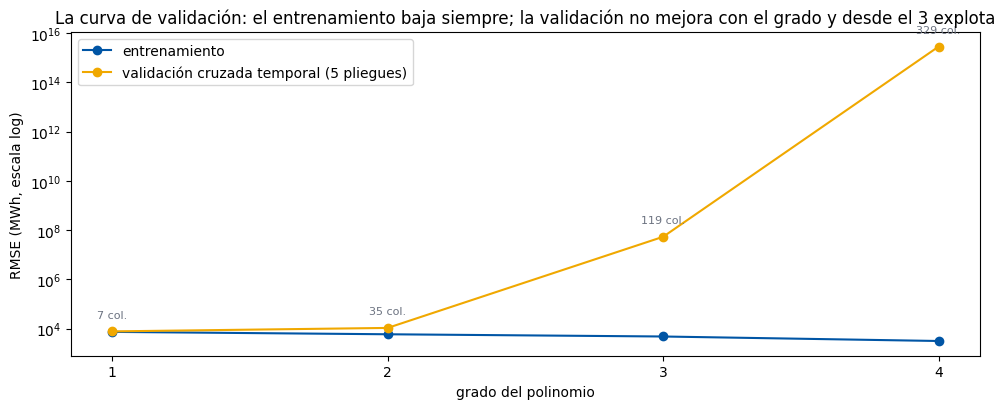

,columnas,RMSE entrenamiento,RMSE validación,± entre pliegues
grado,,,,
1,7,7429.0,7.773000e+03,1.622000e+03
2,35,5944.0,1.075100e+04,4.742000e+03
3,119,4826.0,5.370512e+07,1.072968e+08
4,329,3169.0,2.802757e+15,5.605514e+15


In [13]:
from sklearn.model_selection import cross_val_score, GridSearchCV

grados = [1, 2, 3, 4]
err_ent, err_val, err_val_sd, columnas = [], [], [], []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for g in grados:
        m = flujo(g, LinearRegression())
        cv = -cross_val_score(m, X_ent, y_ent, cv=CV, scoring="neg_root_mean_squared_error")
        m.fit(X_ent, y_ent)
        err_ent.append(rmse(y_ent, m.predict(X_ent))); err_val.append(cv.mean()); err_val_sd.append(cv.std()); columnas.append(m[1].n_output_features_)
err_ent, err_val, err_val_sd = map(np.array, (err_ent, err_val, err_val_sd))

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(grados, err_ent, marker="o", color=AZUL, label="entrenamiento")
ax.plot(grados, err_val, marker="o", color=AMBAR, label="validación cruzada temporal (5 pliegues)")
for g, e, col in zip(grados, err_val, columnas): ax.annotate(f"{col} col.", (g, e), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=8, color=GRIS)
ax.set_yscale("log"); ax.set_xticks(grados); ax.set_xlabel("grado del polinomio"); ax.set_ylabel("RMSE (MWh, escala log)"); ax.legend()
ax.set_title("La curva de validación: el entrenamiento baja siempre; la validación no mejora con el grado y desde el 3 explota")
plt.tight_layout(); plt.show()
pd.DataFrame({"columnas": columnas, "RMSE entrenamiento": err_ent.round(0), "RMSE validación": err_val.round(0), "± entre pliegues": err_val_sd.round(0)}, index=pd.Index(grados, name="grado"))

In [14]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    busqueda = GridSearchCV(flujo(1, LinearRegression()), param_grid={"polynomialfeatures__degree": [1, 2, 3]},
                            cv=CV, scoring="neg_root_mean_squared_error").fit(X_ent, y_ent)
print(f"Mejor grado según la búsqueda (sin freno): {busqueda.best_params_['polynomialfeatures__degree']}  (RMSE de validación {-busqueda.best_score_:,.0f})")

Mejor grado según la búsqueda (sin freno): 1  (RMSE de validación 7,773)


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Sin freno, la validación cruzada elige el grado 1: la polinómica no paga lo que cuesta. En el gimnasio la curva bajaba hasta el grado 2 y después subía; acá es plana o sube desde el principio, y en el grado 3 se dispara a errores de cientos de miles de MWh. La causa es la que se vio con una sola columna: los cubos de valores de un millón de MWh extrapolan sin control en los pliegues donde aparece un agente más grande que los del entrenamiento.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Esto <b>no</b> dice que el grado 2 sea inútil: dice que el grado 2 <b>sin freno</b> lo es. La sección 5 repite la pregunta con regularización.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Leer las curvas de aprendizaje</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Grado 1, 2 y 3, con pliegues temporales. Meseta alta y juntas: falta capacidad. Brecha: memoriza.</p></div>

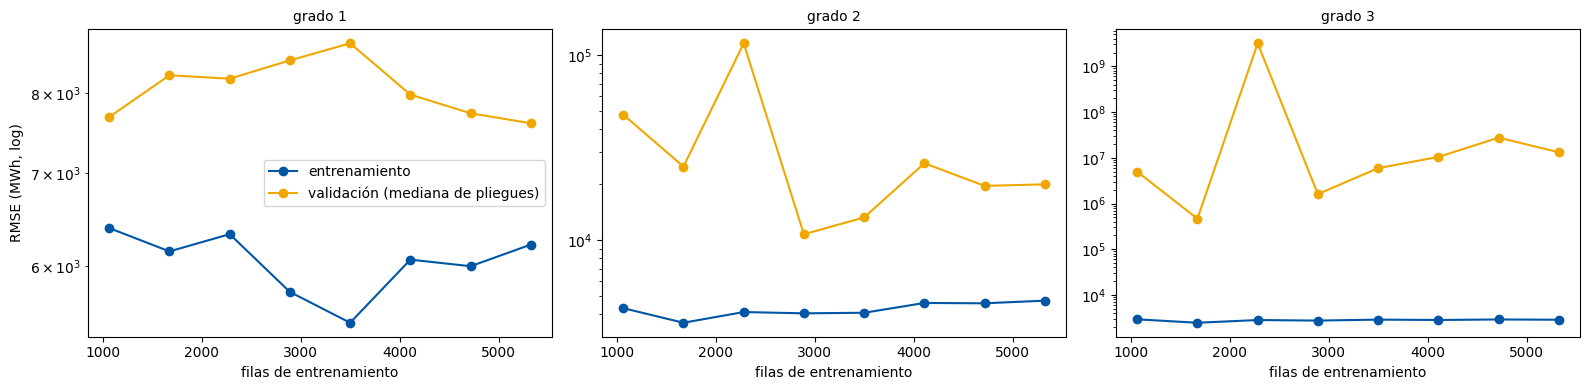

In [15]:
from sklearn.model_selection import learning_curve

fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for ax, g in zip(ejes, [1, 2, 3]):
        tam, e_ent, e_val = learning_curve(flujo(g, LinearRegression()), X_ent, y_ent, cv=CV, train_sizes=np.linspace(0.2, 1.0, 8), scoring="neg_root_mean_squared_error")
        ax.plot(tam, -e_ent.mean(axis=1), marker="o", color=AZUL, label="entrenamiento")
        ax.plot(tam, np.median(-e_val, axis=1), marker="o", color=AMBAR, label="validación (mediana de pliegues)")
        ax.set_yscale("log"); ax.set_title(f"grado {g}", fontsize=10); ax.set_xlabel("filas de entrenamiento")
ejes[0].set_ylabel("RMSE (MWh, log)"); ejes[0].legend()
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Grado 1: las dos curvas cerca, meseta. Grado 2: el entrenamiento baja más que en la recta, pero la validación no lo acompaña: aparece la brecha. Grado 3: la brecha es enorme y la validación salta según el tamaño. Se usa la mediana de los pliegues porque un solo pliegue con un error explosivo arrastraría el promedio.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">5 · Los frenos: regularización y detención temprana</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">5.1 · Ridge: achicar todos los pesos</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">Ridge(alpha=...)</code> suma α‖w‖² al costo. Acá α no se elige a ojo: primero se busca con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">GridSearchCV</code> y validación temporal, y después se barre α para ver los caminos de los pesos y el error.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Ojo con la escala de α: el término de error está en MWh², que son números enormes, así que los α útiles acá son mucho más grandes que en el gimnasio. α no tiene unidades universales: depende de los datos.</p></div>

α elegido por validación cruzada temporal: 1,000  (RMSE de validación 9,370)
Sobre prueba → RMSE = 8,478  (grado 2 sin freno: 10,063)


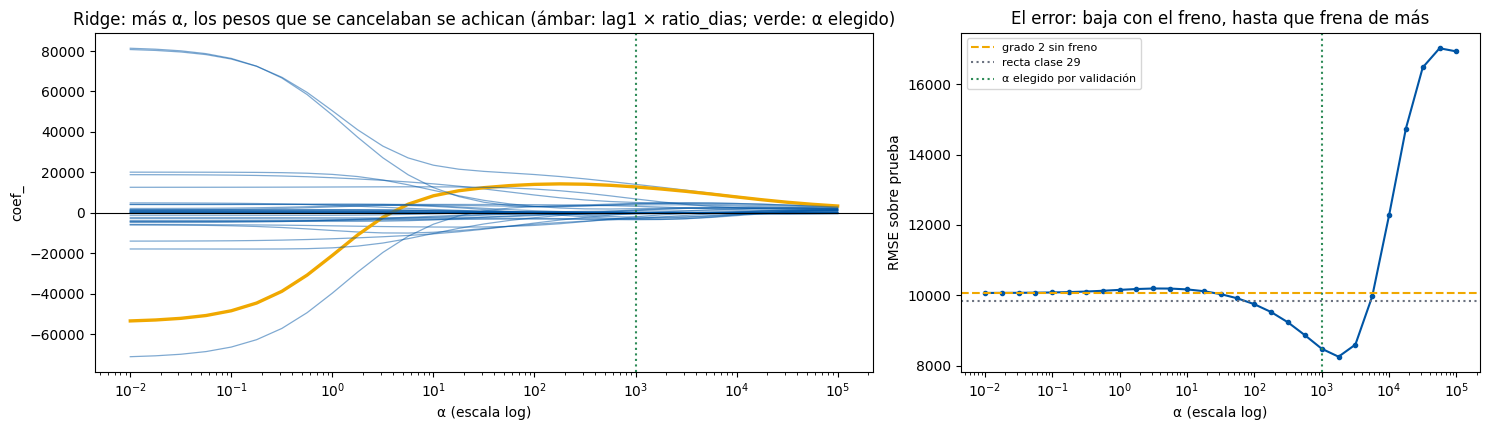

In [16]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet

busca_ridge = GridSearchCV(flujo(2, Ridge()), {"ridge__alpha": np.logspace(0, 5, 11)}, cv=CV, scoring="neg_root_mean_squared_error").fit(X_ent, y_ent)
ALPHA_RIDGE = busca_ridge.best_params_["ridge__alpha"]
print(f"α elegido por validación cruzada temporal: {ALPHA_RIDGE:,.0f}  (RMSE de validación {-busca_ridge.best_score_:,.0f})")
ridge = registrar(f"grado 2 + Ridge(α={ALPHA_RIDGE:,.0f})", flujo(2, Ridge(alpha=ALPHA_RIDGE)))
print(f"Sobre prueba → RMSE = {resultados[f'grado 2 + Ridge(α={ALPHA_RIDGE:,.0f})']['RMSE']:,.0f}  (grado 2 sin freno: {resultados['polinómica grado 2']['RMSE']:,.0f})")

PRODUCTO = "lag1 × ratio_dias"
alphas = np.logspace(-2, 5, 29)
caminos_ridge, err_ridge = [], []
for a in alphas:
    m = flujo(2, Ridge(alpha=a)).fit(X_ent, y_ent)
    caminos_ridge.append(m[-1].coef_); err_ridge.append(rmse(y_pru, m.predict(X_pru)))
caminos_ridge = pd.DataFrame(caminos_ridge, index=alphas, columns=nombres(polinomica))

fig, (a, b) = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw={"width_ratios": [3, 2]})
for col in caminos_ridge.columns:
    es = col == PRODUCTO
    a.plot(alphas, caminos_ridge[col], lw=2.4 if es else 0.9, color=AMBAR if es else AZUL, alpha=1 if es else 0.5)
a.axvline(ALPHA_RIDGE, color=VERDE, ls=":", lw=1.5); a.set_xscale("log"); a.axhline(0, color="black", lw=0.8); a.set_xlabel("α (escala log)"); a.set_ylabel("coef_")
a.set_title(f"Ridge: más α, los pesos que se cancelaban se achican (ámbar: {PRODUCTO}; verde: α elegido)")
b.plot(alphas, err_ridge, marker="o", ms=3, color=AZUL); b.set_xscale("log")
b.axhline(resultados["polinómica grado 2"]["RMSE"], color=AMBAR, ls="--", lw=1.5, label="grado 2 sin freno")
b.axhline(resultados["recta clase 29 (6 predictoras)"]["RMSE"], color=GRIS, ls=":", lw=1.5, label="recta clase 29")
b.axvline(ALPHA_RIDGE, color=VERDE, ls=":", lw=1.5, label="α elegido por validación")
b.set_xlabel("α (escala log)"); b.set_ylabel("RMSE sobre prueba"); b.legend(fontsize=8); b.set_title("El error: baja con el freno, hasta que frena de más")
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con α chico, Ridge es la polinómica sin freno: los pesos enormes que se cancelaban. A medida que α crece esos pares se achican juntos y el error <b>baja</b>, por debajo de la recta. Pasado cierto punto el freno aplasta también lo que sirve y el error vuelve a subir. El α que eligió la validación cruzada (sin mirar la prueba) cae en la zona buena.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Más α, más plano</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Una sola predictora (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1</code>) a grado 20 y Ridge con distintos α, en el zoom del 99 % de los agentes.</p></div>

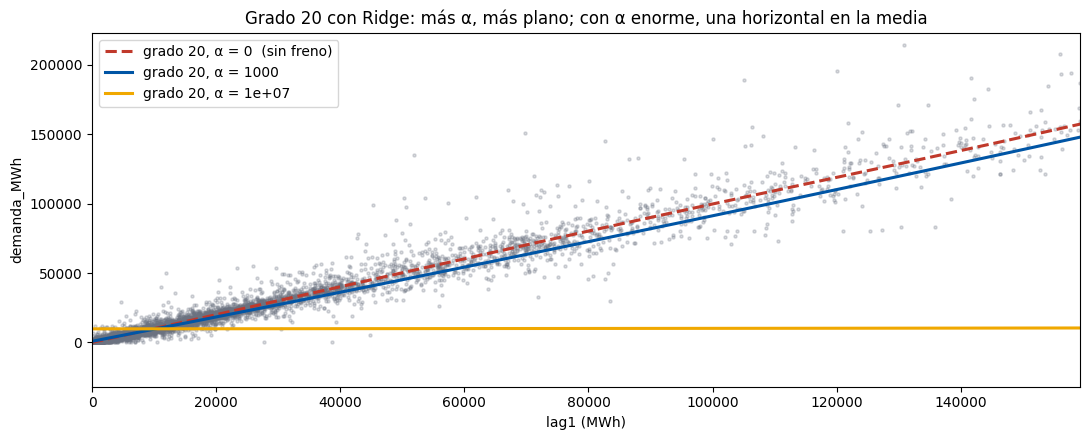

In [17]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.scatter(ent1["lag1"], ent1[OBJETIVO], s=5, alpha=0.25, color=GRIS)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for a, color, ls in [(0, ROJO, "--"), (1e3, AZUL, "-"), (1e7, AMBAR, "-")]:
        modelo_a = LinearRegression() if a == 0 else Ridge(alpha=a)
        m = make_pipeline(PolynomialFeatures(degree=20, include_bias=False), StandardScaler(), modelo_a).fit(ent1[["lag1"]], ent1[OBJETIVO])
        ax.plot(xs, m.predict(xs), color=color, lw=2.2, ls=ls, label=f"grado 20, α = {a:g}" + ("  (sin freno)" if a == 0 else ""))
ax.set_xlim(0, lim); ax.set_ylim(-0.2 * lim, 1.4 * lim); ax.set_xlabel("lag1 (MWh)"); ax.set_ylabel(OBJETIVO); ax.legend()
ax.set_title("Grado 20 con Ridge: más α, más plano; con α enorme, una horizontal en la media")
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">5.2 · Lasso: algunos pesos en cero</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">Lasso</code> con ℓ1 lleva pesos a cero: selecciona columnas. Mismo procedimiento: α por validación, después el barrido.</p></div>

α elegido por validación: 316 (RMSE validación 8,991) → prueba RMSE = 8,308 · pesos ≠ 0: 9 de 35


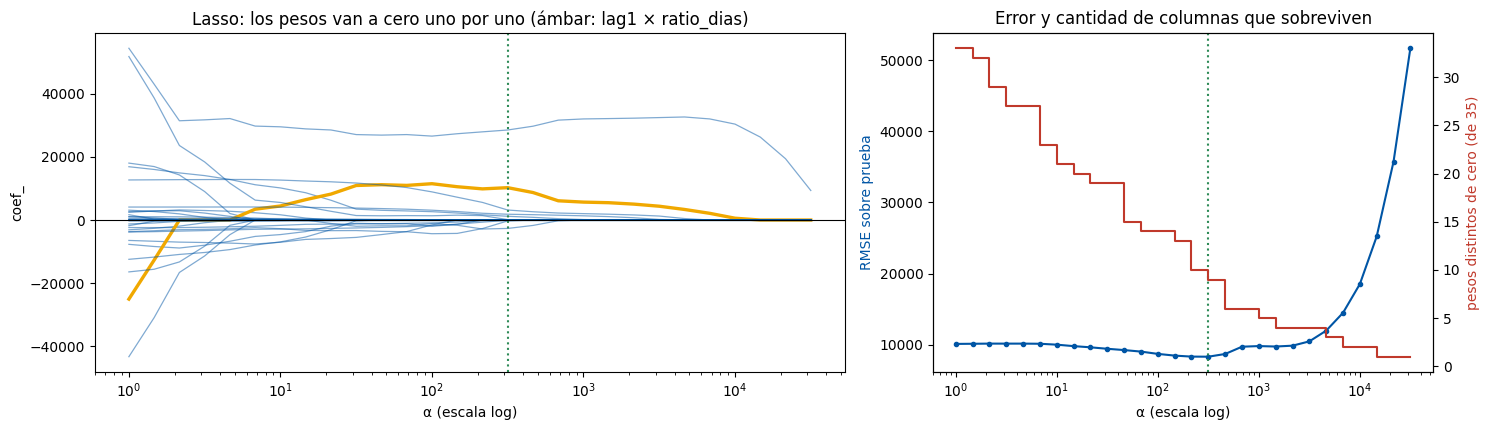

In [18]:
from sklearn.linear_model import lasso_path

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    # 1) α por validación cruzada temporal (lo lento: 45 ajustes; n_jobs=-1 usa todos los núcleos de tu compu)
    busca_lasso = GridSearchCV(flujo(2, Lasso(max_iter=20000)), {"lasso__alpha": np.logspace(0, 4, 9)},
                               cv=CV, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(X_ent, y_ent)
    ALPHA_LASSO = busca_lasso.best_params_["lasso__alpha"]
    NOMBRE_LASSO = f"grado 2 + Lasso(α={ALPHA_LASSO:,.0f})"
    lasso = registrar(NOMBRE_LASSO, flujo(2, Lasso(alpha=ALPHA_LASSO, max_iter=20000)))
    print(f"α elegido por validación: {ALPHA_LASSO:,.0f} (RMSE validación {-busca_lasso.best_score_:,.0f}) → prueba RMSE = {resultados[NOMBRE_LASSO]['RMSE']:,.0f} · pesos ≠ 0: {np.sum(lasso[-1].coef_ != 0)} de 35")

    # 2) El barrido para el gráfico: se prepara una sola vez y lasso_path calcula todos los α juntos
    alphas_l = np.logspace(0, 4.5, 28)
    prep_l = preparar(2).fit(X_ent)
    Xe_l, Xp_l = prep_l.transform(X_ent), prep_l.transform(X_pru)
    y_media = y_ent.mean()                                   # columnas escaladas con media 0: el sesgo es la media de y
    alphas_out, coefs_l, _ = lasso_path(Xe_l, y_ent.to_numpy() - y_media, alphas=alphas_l, max_iter=20000)
    orden_a = np.argsort(alphas_out)                         # lasso_path los devuelve de mayor a menor
    alphas_l, coefs_l = alphas_out[orden_a], coefs_l[:, orden_a].T
    err_lasso = [rmse(y_pru, Xp_l @ w + y_media) for w in coefs_l]
    no_cero = [int(np.sum(w != 0)) for w in coefs_l]
caminos_lasso = pd.DataFrame(coefs_l, index=alphas_l, columns=nombres(polinomica))

fig, (a, b) = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw={"width_ratios": [3, 2]})
for col in caminos_lasso.columns:
    es = col == PRODUCTO
    a.plot(alphas_l, caminos_lasso[col], lw=2.4 if es else 0.9, color=AMBAR if es else AZUL, alpha=1 if es else 0.5)
a.axvline(ALPHA_LASSO, color=VERDE, ls=":", lw=1.5); a.set_xscale("log"); a.axhline(0, color="black", lw=0.8); a.set_xlabel("α (escala log)"); a.set_ylabel("coef_")
a.set_title(f"Lasso: los pesos van a cero uno por uno (ámbar: {PRODUCTO})")
b.plot(alphas_l, err_lasso, marker="o", ms=3, color=AZUL); b.set_xscale("log"); b.set_xlabel("α (escala log)"); b.set_ylabel("RMSE sobre prueba", color=AZUL)
b.axvline(ALPHA_LASSO, color=VERDE, ls=":", lw=1.5)
b2 = b.twinx(); b2.plot(alphas_l, no_cero, color=ROJO, lw=1.5, drawstyle="steps-post"); b2.set_ylabel("pesos distintos de cero (de 35)", color=ROJO)
b.set_title("Error y cantidad de columnas que sobreviven")
plt.tight_layout(); plt.show()

In [19]:
sobreviven = pd.Series(lasso[-1].coef_, index=nombres(lasso))
sobreviven = sobreviven[sobreviven != 0].reindex(sobreviven[sobreviven != 0].abs().sort_values(ascending=False).index)
print(f"{NOMBRE_LASSO}: {len(sobreviven)} columnas de 35. Las que sobreviven, y su peso (MWh por desvío):")
print(sobreviven.round(0).to_string())

grado 2 + Lasso(α=316): 9 columnas de 35. Las que sobreviven, y su peso (MWh por desvío):
lag1                      28549.0
lag1 × ratio_dias         10259.0
lag12^2                    3170.0
lag2^2                    -2669.0
lag12 × es_residencial     1832.0
lag1 × mes_num             1184.0
lag2 × lag12               -282.0
lag2 × ratio_dias           119.0
lag12 × mes_num             -77.0


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Lasso hace solo lo que en la sección 1 se dedujo a mano: de 35 columnas se queda con unas pocas, y arriba de todo quedan <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1</code> y el producto <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1 × ratio_dias</code>. Los pares de rezagos que se cancelaban desaparecen: entre dos columnas casi iguales, Lasso se queda con una. Es el modelo más chico, y el de mejor error.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">5.3 · Elastic Net: las dos normas mezcladas</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">ElasticNet(alpha, l1_ratio=r)</code>: r = 1 es Lasso, r = 0 es Ridge. Se barre r con α = 0,1 fijo.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Teoría y práctica.</b> En scikit-learn el α de Ridge y el de Lasso / Elastic Net no están en la misma escala: Lasso y Elastic Net dividen el error por 2n. Por eso con α = 0,1 Elastic Net ya frena bastante, mientras Ridge necesitaba α de miles. Y por la misma razón no conviene probar Elastic Net con el α que eligió Lasso: la parte ℓ2 de la mezcla, con ese α, frenaría muchísimo.</p></div>

In [20]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    enet = registrar("grado 2 + ElasticNet(α=0.1, r=0.5)", flujo(2, ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=50000, precompute=True)))
    filas = []
    for r in [0.05, 0.2, 0.5, 0.8, 0.95, 1.0]:
        m = flujo(2, ElasticNet(alpha=0.1, l1_ratio=r, max_iter=50000, precompute=True)).fit(X_ent, y_ent)   # precompute: usa XᵀX (35×35) en vez de recorrer las 32 000 filas
        filas.append({"l1_ratio (r)": r, "pesos ≠ 0": int(np.sum(m[-1].coef_ != 0)), "RMSE prueba": rmse(y_pru, m.predict(X_pru))})
pd.DataFrame(filas).set_index("l1_ratio (r)").round(0)

,pesos ≠ 0,RMSE prueba
l1_ratio (r),,
0.05,34,8540.0
0.20,34,8367.0
0.50,34,8265.0
0.80,34,8775.0
0.95,34,9565.0
1.00,33,10069.0


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con α = 0,1 la parte ℓ1 casi no llega a anular pesos (quedan casi todos), pero la parte ℓ2 achica los que se cancelaban y el error baja, con el mejor resultado en una mezcla intermedia. Con r = 1 (Lasso puro con ese α tan chico) el freno es casi nulo y se vuelve a la polinómica sin freno. Es lo que dice la diapositiva: con atributos correlacionados, la mezcla es más estable que Lasso solo.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">5.4 · Dos normas, dos caminos</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Dos pesos, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1</code> y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag12</code> (correlacionados en 0,95), con el objetivo centrado. Cada punto es la solución exacta para un α. Al revés que en el gimnasio, las curvas de nivel son elipses alargadas en diagonal.</p></div>

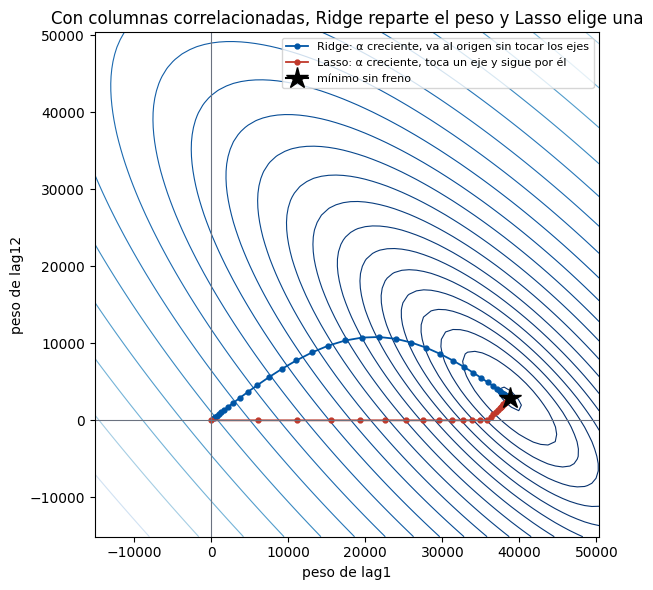

Lasso deja en cero el peso de lag12 a partir de α ≈ 5,163, con lag1 = 35,819. Ridge, con lag1 ≈ 35,877, todavía le da 4,939 a lag12


In [21]:
prep2 = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(X_ent[["lag1", "lag12"]])
X2 = prep2.transform(X_ent[["lag1", "lag12"]]); yc = y_ent.to_numpy() - y_ent.mean()
sol = LinearRegression(fit_intercept=False).fit(X2, yc).coef_
def mse2(t1, t2): return np.mean((X2 @ np.array([t1, t2]) - yc) ** 2)
r_max = 1.3 * np.abs(sol).max()
g1, g2 = np.meshgrid(np.linspace(-0.3 * r_max, r_max, 70), np.linspace(-0.3 * r_max, r_max, 70))
Z = np.vectorize(mse2)(g1, g2)
alpha_max = np.abs(X2.T @ yc).max() / len(yc)                      # con este α Lasso deja todo en cero
alphas2 = np.geomspace(alpha_max / 500, alpha_max, 40)
alphas_r = np.geomspace(1e-3, 1e2, 40) * len(yc)                      # Ridge con su propio rango de α: los pesos están en decenas de miles
cam_r = np.array([Ridge(alpha=a, fit_intercept=False).fit(X2, yc).coef_ for a in alphas_r])
cam_l = np.array([Lasso(alpha=a, fit_intercept=False, max_iter=20000).fit(X2, yc).coef_ for a in alphas2])

fig, ax = plt.subplots(figsize=(9, 6))
ax.contour(g1, g2, Z, levels=np.geomspace(Z.min() * 1.02, Z.max(), 22), cmap="Blues_r", linewidths=0.8)
ax.plot(cam_r[:, 0], cam_r[:, 1], marker="o", ms=3.5, color=AZUL, lw=1.3, label="Ridge: α creciente, va al origen sin tocar los ejes")
ax.plot(cam_l[:, 0], cam_l[:, 1], marker="o", ms=3.5, color=ROJO, lw=1.3, label="Lasso: α creciente, toca un eje y sigue por él")
ax.plot(*sol, marker="*", ms=16, color="black", label="mínimo sin freno"); ax.axhline(0, color=GRIS, lw=0.8); ax.axvline(0, color=GRIS, lw=0.8)
ax.set_xlabel("peso de lag1"); ax.set_ylabel("peso de lag12"); ax.legend(loc="upper right", fontsize=8); ax.set_aspect("equal")
ax.set_title("Con columnas correlacionadas, Ridge reparte el peso y Lasso elige una")
plt.tight_layout(); plt.show()
toca = next((a for a, w in zip(alphas2, cam_l) if w[1] == 0), None)
if toca is not None:
    w_l = cam_l[list(alphas2).index(toca)]
    j = np.argmin(np.abs(cam_r[:, 0] - w_l[0]))                       # el punto del camino de Ridge con un peso de lag1 parecido
    print(f"Lasso deja en cero el peso de lag12 a partir de α ≈ {toca:,.0f}, con lag1 = {w_l[0]:,.0f}. Ridge, con lag1 ≈ {cam_r[j, 0]:,.0f}, todavía le da {cam_r[j, 1]:,.0f} a lag12")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El valle alargado de la clase 29 otra vez. Ridge baja hacia el origen repartiendo el peso entre las dos columnas: con el mismo freno, a <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag12</code> todavía le deja una parte. Lasso, en cambio, enseguida manda <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag12</code> a cero y se queda solo con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1</code>, que es la que más explica. Con predictoras muy correlacionadas eso es una ventaja para leer el modelo y un riesgo si cambia la muestra: Lasso puede elegir una u otra casi al azar.</p></div>

<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">5.5 · Sin escalar: la penalización depende de la escala</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El mismo freno sin el escalador. Acá las columnas expandidas van de 0/1 a <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1²</code>, que llega a 10¹²: el contraste es todavía más extremo que en el gimnasio.</p></div>

RMSE prueba  pesos ≠ 0              mayor |peso|
freno          escalado                                                     
Ridge(α=1,000) sin escalar      10059.0         34      mes_num × ratio_dias
               con escalar       8478.0         34                      lag1
Lasso(α=316)   sin escalar      10191.0         23  mes_num × es_residencial
               con escalar       8308.0          9                      lag1

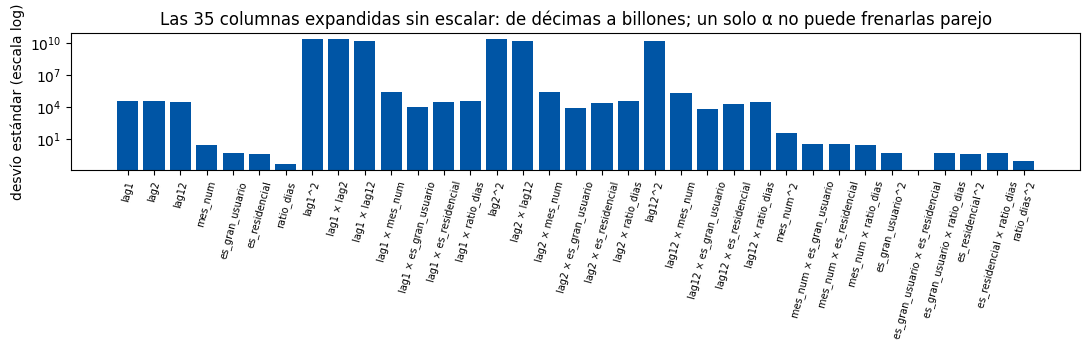

In [22]:
from sklearn.base import clone

filas = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for nombre_f, modelo_r in [(f"Ridge(α={ALPHA_RIDGE:,.0f})", Ridge(alpha=ALPHA_RIDGE)), (f"Lasso(α={ALPHA_LASSO:,.0f})", Lasso(alpha=ALPHA_LASSO, max_iter=5000))]:
        sin = make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True), PolynomialFeatures(degree=2, include_bias=False), clone(modelo_r)).fit(X_ent, y_ent)
        con = flujo(2, clone(modelo_r)).fit(X_ent, y_ent)
        for etiqueta, m in [("sin escalar", sin), ("con escalar", con)]:
            filas.append({"freno": nombre_f, "escalado": etiqueta, "RMSE prueba": rmse(y_pru, m.predict(X_pru)), "pesos ≠ 0": int(np.sum(m[-1].coef_ != 0)),
                          "mayor |peso|": pd.Series(np.abs(m[-1].coef_), index=nombres(m)).idxmax()})
display(pd.DataFrame(filas).set_index(["freno", "escalado"]).round(0))

fig, ax = plt.subplots(figsize=(11, 3.6))
col_exp = pd.Series(PolynomialFeatures(degree=2, include_bias=False).fit_transform(imputador.transform(X_ent)).std(axis=0), index=nombres(polinomica))
ax.bar(range(len(col_exp)), col_exp.values, color=AZUL); ax.set_yscale("log"); ax.set_xticks(range(len(col_exp))); ax.set_xticklabels(col_exp.index, rotation=75, fontsize=7)
ax.set_ylabel("desvío estándar (escala log)"); ax.set_title("Las 35 columnas expandidas sin escalar: de décimas a billones; un solo α no puede frenarlas parejo")
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Sin escalar, el mismo α frena muchísimo a las columnas de valores chicos (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">ratio_dias</code>, los 0/1, el mes) y nada a las de valores enormes (los cuadrados y productos de rezagos), porque un peso sobre una columna de 10¹² es diminuto y la penalización no lo ve. Cambian el error, la cantidad de pesos y cuál es el más grande. El escalado va siempre antes del freno.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">5.6 · Grado alto con freno</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">En la clase el grado 10 con Ridge daba un modelo usable. Con 7 columnas, el grado 10 generaría más de 19 000 columnas para 32 000 filas (varios GB en memoria), así que se usa el grado 5: 791 columnas.</p></div>

In [23]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    g5 = registrar("grado 5 sin freno", flujo(5, LinearRegression()))
    g5_r1 = registrar(f"grado 5 + Ridge(α={ALPHA_RIDGE:,.0f})", flujo(5, Ridge(alpha=ALPHA_RIDGE)))
    g5_r2 = registrar(f"grado 5 + Ridge(α={ALPHA_RIDGE * 10:,.0f})", flujo(5, Ridge(alpha=ALPHA_RIDGE * 10)))
print(f"columnas expandidas: {g5[1].n_output_features_}")
for k in ["grado 5 sin freno", f"grado 5 + Ridge(α={ALPHA_RIDGE:,.0f})", f"grado 5 + Ridge(α={ALPHA_RIDGE * 10:,.0f})"]:
    print(f"{k:28s} RMSE entrenamiento = {rmse(y_ent, resultados[k]['modelo'].predict(X_ent)):11,.0f}   RMSE prueba = {resultados[k]['RMSE']:13,.0f}   ajuste {resultados[k]['ajuste (ms)']:,.0f} ms")

columnas expandidas: 791
grado 5 sin freno            RMSE entrenamiento =       2,435   RMSE prueba =     1,493,401   ajuste 4,239 ms
grado 5 + Ridge(α=1,000)     RMSE entrenamiento =       5,422   RMSE prueba =        32,236   ajuste 1,261 ms
grado 5 + Ridge(α=10,000)    RMSE entrenamiento =       7,115   RMSE prueba =        25,459   ajuste 1,258 ms


<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Acá el resultado es distinto al de la clase, y vale la pena decirlo. El grado 5 sin freno ajusta el entrenamiento muy bien y en prueba da errores de millones. Con Ridge mejora muchísimo, pero sigue lejos de la recta. Con un solo agente gigante en prueba que cae fuera del rango del entrenamiento, una potencia quinta de un millón de MWh extrapola tan lejos que ningún α razonable lo contiene. El freno reemplaza en parte a elegir bien el grado, pero no del todo: con colas tan largas, el grado bajo sigue siendo parte de la solución.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">5.7 · Parar a tiempo</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La detención temprana: entrenar época por época, medir la validación después de cada una, guardar la mejor copia y, con paciencia, volver a ella.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Diferencia con la clase:</b> allá se usó <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">SGDRegressor.partial_fit</code>. Con estos datos el estocástico sobre columnas expandidas diverge con cualquier tasa razonable: una sola fila de una distribuidora gigante, al cuadrado, da un paso que tira todo afuera. Por eso se usa el descenso de gradiente por lotes completos de la clase 29 (el mismo bucle, con la mitad de la tasa límite para que baje sin zigzaguear), sobre grado 3 y sin penalización. Se aparta el último 20 % del entrenamiento, en orden temporal, como validación; la prueba sigue intacta.</p></div>

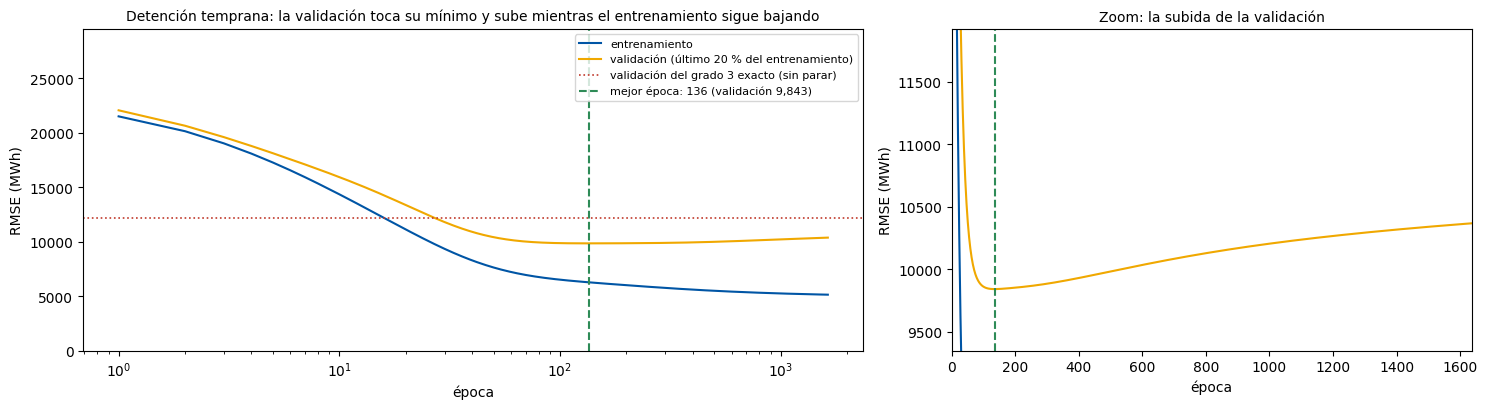

Se detuvo en la época 1636 · mejor época 136 · prueba con la copia guardada: RMSE = 19,982
Grado 3 exacto (ecuación normal, sin parar): RMSE prueba = 21,456


In [24]:
from copy import deepcopy

corte_v = int(len(X_ent) * 0.8)                                       # validación: el tramo final del entrenamiento, en el tiempo
X_e, y_e, X_v, y_v = X_ent.iloc[:corte_v], y_ent.iloc[:corte_v].to_numpy(), X_ent.iloc[corte_v:], y_ent.iloc[corte_v:].to_numpy()
prep3 = preparar(3).fit(X_e)
A_e = np.c_[np.ones(len(X_e)), prep3.transform(X_e)]; A_v = np.c_[np.ones(len(X_v)), prep3.transform(X_v)]; A_p = np.c_[np.ones(len(X_pru)), prep3.transform(X_pru)]
G, b_ = A_e.T @ A_e / len(A_e), A_e.T @ y_e / len(A_e)                # se precalcula XᵀX/m: cada época cuesta lo mismo que con pocas columnas
eta = 1.0 / np.linalg.eigvalsh(2 * G).max()                           # la mitad del límite 2/λmax de la clase 29: baja sin zigzaguear

theta = np.zeros(A_e.shape[1])
EPOCAS, PACIENCIA = 6000, 1500
curva_e, curva_v = [], []
mejor, mejor_epoca, guardado = np.inf, 0, None
t0 = time.perf_counter()
for epoca in range(1, EPOCAS + 1):
    theta -= eta * 2 * (G @ theta - b_)                               # una época de gradiente
    err = rmse(y_v, A_v @ theta)
    if err < mejor: mejor, mejor_epoca, guardado = err, epoca, theta.copy()
    curva_e.append(rmse(y_e, A_e @ theta)); curva_v.append(err)
    if epoca - mejor_epoca >= PACIENCIA: break
t_det = (time.perf_counter() - t0) * 1000
exacto = np.linalg.lstsq(A_e, y_e, rcond=None)[0]
NOMBRE_DET = f"grado 3 + gradiente detenido (época {mejor_epoca})"
guardar(NOMBRE_DET, A_p @ guardado, t_det)

fig, (ax, z) = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [3, 2]})
epocas = np.arange(1, len(curva_v) + 1)
for a in (ax, z):
    a.plot(epocas, curva_e, color=AZUL, label="entrenamiento")
    a.plot(epocas, curva_v, color=AMBAR, label="validación (último 20 % del entrenamiento)")
    a.axhline(rmse(y_v, A_v @ exacto), color=ROJO, ls=":", lw=1.2, label="validación del grado 3 exacto (sin parar)")
    a.axvline(mejor_epoca, color=VERDE, ls="--", lw=1.5, label=f"mejor época: {mejor_epoca} (validación {mejor:,.0f})")
    a.set_xlabel("época"); a.set_ylabel("RMSE (MWh)")
ax.set_xscale("log"); ax.set_ylim(0, 3 * mejor); ax.legend(loc="upper right", fontsize=8); ax.set_title("Detención temprana: la validación toca su mínimo y sube mientras el entrenamiento sigue bajando", fontsize=10)
z.set_xlim(0, len(curva_v)); z.set_ylim(mejor * 0.95, max(curva_v[-1], mejor) * 1.15); z.set_title("Zoom: la subida de la validación", fontsize=10)
plt.tight_layout(); plt.show()
print(f"Se detuvo en la época {len(curva_v)} · mejor época {mejor_epoca} · prueba con la copia guardada: RMSE = {resultados[NOMBRE_DET]['RMSE']:,.0f}")
print(f"Grado 3 exacto (ecuación normal, sin parar): RMSE prueba = {rmse(y_pru, A_p @ exacto):,.0f}")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Ahora la curva es la de la diapositiva: el entrenamiento baja siempre; la validación baja, toca su mínimo alrededor de la época 100 y después sube despacio, mientras el gradiente acomoda los pesos de las columnas cúbicas para el entrenamiento. Sobre la validación, la copia guardada queda muy por debajo del grado 3 resuelto hasta el final (la línea roja).</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Sobre la <b>prueba</b>, en cambio, la mejora es chica y el resultado sigue siendo peor que la recta. La validación es el tramo final del entrenamiento (principios de 2019), y la prueba es otro período, con agentes gigantes donde los cubos extrapolan. Parar a tiempo frena el sobreajuste, pero no arregla un grado demasiado alto para estos datos: no elige columnas, solo deja de aprender. Por eso, de los tres frenos, el que gana acá es Lasso.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">6 · El comparativo: cuál resultó mejor, y cómo se elige</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La matriz, el error y el costo</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Todo lo registrado. Se sacan los modelos con errores explosivos (más de 5 veces la línea de base de la media) porque aplastan la escala de color; ya se vieron arriba.</p></div>

In [25]:
matriz = pd.DataFrame({k: {m: v[m] for m in ["RMSE", "MAE", "R²", "ajuste (ms)"]} for k, v in resultados.items()}).T.astype(float)
explosivos = matriz.index[matriz["RMSE"] > 5 * resultados["línea de base (media)"]["RMSE"]]
print("Fuera de la tabla por error explosivo:", list(explosivos))
matriz = matriz.drop(index=explosivos)
(matriz.style.format({"RMSE": "{:,.0f}", "MAE": "{:,.0f}", "R²": "{:.4f}", "ajuste (ms)": "{:.1f}"})
       .background_gradient(subset=["RMSE", "MAE", "ajuste (ms)"], cmap="RdYlGn_r")
       .background_gradient(subset=["R²"], cmap="RdYlGn"))

Fuera de la tabla por error explosivo: ['grado 5 sin freno']


,RMSE,MAE,R²,ajuste (ms)
línea de base (media),"66,699","17,949",-0.0047,1.5
mes anterior,"10,463","1,545",0.9753,0.0
mes anterior × ratio_dias,"9,343","1,383",0.9803,0.0
recta clase 29 (6 predictoras),"9,825","1,605",0.9782,0.0
"recta (grado 1, 7 predictoras)","9,811","1,615",0.9783,37.7
polinómica grado 2,"10,063","1,668",0.9771,126.6
"grado 2 + Ridge(α=1,000)","8,478","1,516",0.9838,101.0
grado 2 + Lasso(α=316),"8,308","1,425",0.9844,2602.1
"grado 2 + ElasticNet(α=0.1, r=0.5)","8,265","1,535",0.9846,142.8
"grado 5 + Ridge(α=1,000)","32,236","2,413",0.7653,1261.0


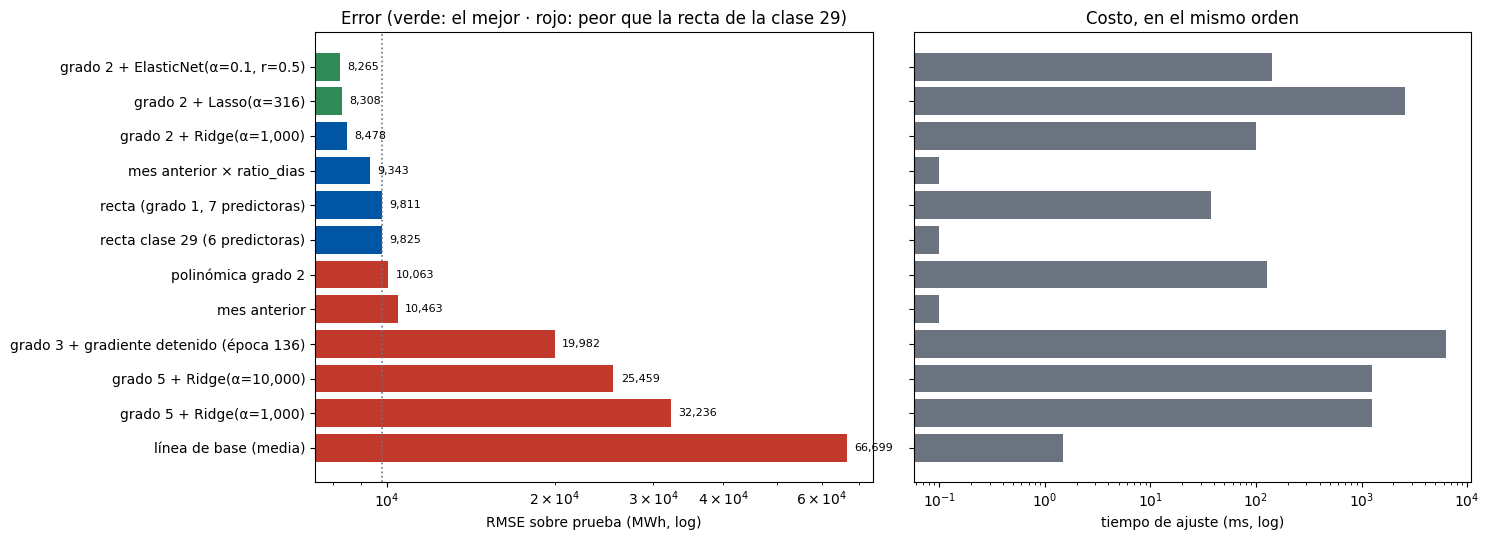

In [26]:
fig, (a, b) = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
orden = matriz.sort_values("RMSE")
mejor_rmse = orden["RMSE"].min()
ref = resultados["recta clase 29 (6 predictoras)"]["RMSE"]
colores = [VERDE if r <= mejor_rmse * 1.02 else (ROJO if r > ref else AZUL) for r in orden["RMSE"]]
a.barh(orden.index, orden["RMSE"], color=colores); a.invert_yaxis(); a.set_xscale("log"); a.set_xlabel("RMSE sobre prueba (MWh, log)")
a.axvline(ref, color=GRIS, ls=":", lw=1.2); a.set_title("Error (verde: el mejor · rojo: peor que la recta de la clase 29)")
for i, v in enumerate(orden["RMSE"]): a.text(v * 1.03, i, f"{v:,.0f}", va="center", fontsize=8)
b.barh(orden.index, orden["ajuste (ms)"].clip(lower=0.1), color=GRIS); b.set_xscale("log")
b.set_xlabel("tiempo de ajuste (ms, log)"); b.set_title("Costo, en el mismo orden")
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Fila por fila</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Veinticinco filas de prueba ordenadas por demanda real, con la recta, la polinómica sin freno y las dos frenadas.</p></div>

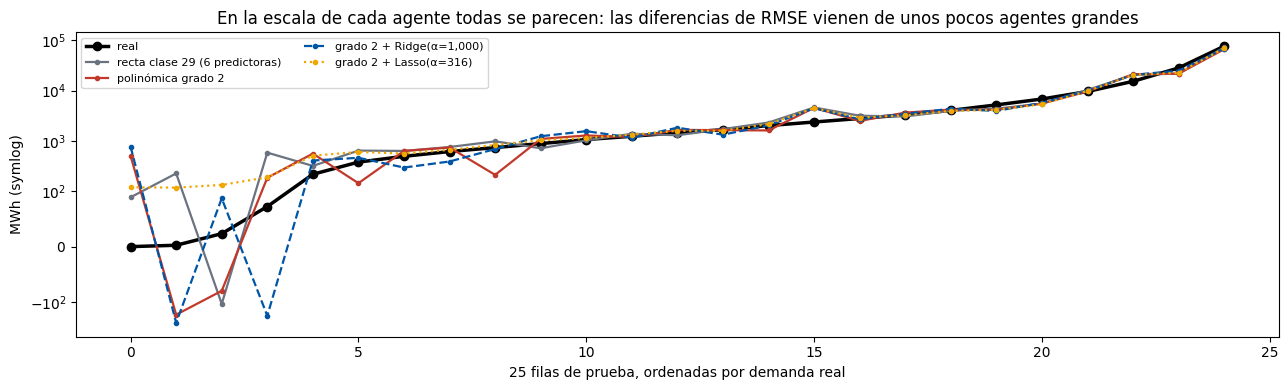

In [27]:
muestra = np.argsort(y_pru.to_numpy())[::len(y_pru) // 25][:25]
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(y_pru.to_numpy()[muestra], color="black", lw=2.5, marker="o", label="real")
for nombre, color, ls in [("recta clase 29 (6 predictoras)", GRIS, "-"), ("polinómica grado 2", ROJO, "-"), (f"grado 2 + Ridge(α={ALPHA_RIDGE:,.0f})", AZUL, "--"), (NOMBRE_LASSO, AMBAR, ":")]:
    Xm = X_pru29 if "clase 29" in nombre else X_pru
    ax.plot(resultados[nombre]["modelo"].predict(Xm.iloc[muestra]), color=color, lw=1.6, ls=ls, marker=".", label=nombre)
ax.set_yscale("symlog", linthresh=100); ax.set_xlabel("25 filas de prueba, ordenadas por demanda real"); ax.set_ylabel("MWh (symlog)"); ax.legend(fontsize=8, ncol=2)
ax.set_title("En la escala de cada agente todas se parecen: las diferencias de RMSE vienen de unos pocos agentes grandes")
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La elección</b></div><table style="border-collapse: collapse; width: 100%; font-size: 0.96em; margin-top: 4px;"><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Por validación, no por prueba</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Entre las variantes cuyo α se eligió con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">GridSearchCV</code> temporal, Lasso tuvo menor error de validación que Ridge. Que también gane en prueba confirma la elección; no la decide.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Entre las que empatan, la más simple</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Lasso además usa unas pocas columnas de 35, y la que más pesa después de <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1</code> es el producto <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1 × ratio_dias</code>: el modelo se puede explicar en una frase. Es el que sigue a la sección 7.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Contra la vara honesta</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">La referencia sin aprendizaje «mes anterior × ratio_dias» es muy fuerte. Lasso le gana en RMSE, pero hay que mirar también el MAE en la matriz: en la fila típica las diferencias son chicas. La mejora real está en los agentes grandes.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo que no se elige</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Grados 3 o más (explotan), la polinómica sin freno (sobreajusta por columnas casi iguales) y cualquier freno sin escalar.</td></tr></table></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">7 · Usarlo</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Agentes nuevos, y por qué cada uno recibe su predicción</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El agente 1 de la clase 29 (una distribuidora residencial mediana), con la misma historia, predicho para enero, febrero y marzo; y el agente 2 (gran usuario sin dato de hace un año) para febrero. La recta suma lo mismo por cada mes; Lasso reacciona al largo del mes.</p></div>

In [28]:
final = lasso
base1 = {"lag1": 52000, "lag2": 48000, "lag12": 55000, "es_gran_usuario": 0, "es_residencial": 1}
nuevo = pd.DataFrame([
    {**base1, "mes_num": 1, "ratio_dias": 31 / 31},
    {**base1, "mes_num": 2, "ratio_dias": 28 / 31},
    {**base1, "mes_num": 3, "ratio_dias": 31 / 28},
    {"lag1": 3100, "lag2": 3000, "lag12": np.nan, "mes_num": 2, "es_gran_usuario": 1, "es_residencial": 0, "ratio_dias": 28 / 31},
], index=["agente 1 · enero", "agente 1 · febrero", "agente 1 · marzo", "agente 2 · febrero"])
nuevo["recta clase 29"] = recta.predict(nuevo[PREDICTORAS_29]).round(0)
nuevo["mes anterior × ratio_dias"] = (nuevo["lag1"] * nuevo["ratio_dias"]).round(0)
nuevo["grado 2 + Lasso (predicción)"] = final.predict(nuevo[PREDICTORAS]).round(0)
nuevo

,lag1,lag2,lag12,es_gran_usuario,es_residencial,mes_num,ratio_dias,recta clase 29,mes anterior × ratio_dias,grado 2 + Lasso (predicción)
agente 1 · enero,52000,48000,55000.0,0,1,1,1.000000,54022.0,52000.0,54904.0
agente 1 · febrero,52000,48000,55000.0,0,1,2,0.903226,54080.0,46968.0,53844.0
agente 1 · marzo,52000,48000,55000.0,0,1,3,1.107143,54137.0,57571.0,56719.0
agente 2 · febrero,3100,3000,NaN,1,0,2,0.903226,2765.0,2800.0,2993.0


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La recta sube unos pocos MWh por mes, siempre lo mismo: trata al mes como un número. Lasso baja de enero a febrero y sube con fuerza en marzo, que es lo que pasa en los datos. Pero solo captura una parte del efecto de los días: la corrección «pura» (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1 × ratio_dias</code>) bajaría mucho más en febrero. El coeficiente se ajusta sobre todos los agentes a la vez, y los gigantes, que dominan el error cuadrático, no reaccionan igual que una distribuidora mediana.</p></div>

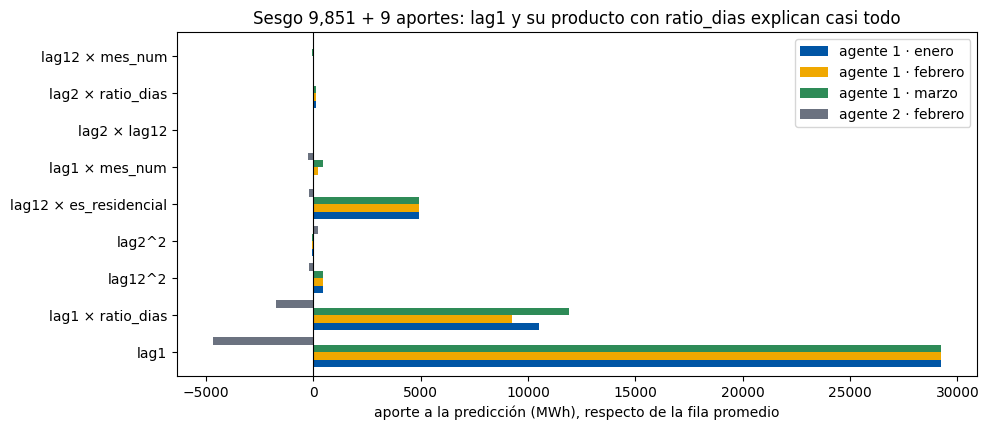

In [29]:
def aportes_de(modelo, X_filas):
    # Aporte de cada columna expandida con peso ≠ 0 (coef × valor escalado), de mayor a menor peso
    Z = pd.DataFrame(modelo[:-1].transform(X_filas), columns=nombres(modelo), index=X_filas.index)
    coefs = pd.Series(modelo[-1].coef_, index=Z.columns)
    con_peso = coefs[coefs != 0].abs().sort_values(ascending=False).index
    return (Z * coefs)[con_peso], Z
ap_nuevo, _ = aportes_de(final, nuevo[PREDICTORAS])
ax = ap_nuevo.T.plot.barh(figsize=(10, 4.4), color=[AZUL, AMBAR, VERDE, GRIS], width=0.8)
ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("aporte a la predicción (MWh), respecto de la fila promedio")
ax.set_title(f"Sesgo {final[-1].intercept_:,.0f} + {ap_nuevo.shape[1]} aportes: lag1 y su producto con ratio_dias explican casi todo")
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Diez filas, con su predicción explicada</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Diez filas de prueba a lo largo del rango (desde el percentil 10, para evitar demandas ≈ 0 donde el error relativo no tiene sentido).</p></div>

In [30]:
orden_real = np.argsort(y_pru.to_numpy())
elegidos = orden_real[np.linspace(0.10 * len(orden_real), len(orden_real) - 1, 10).astype(int)]
X10 = X_pru.iloc[elegidos]
aportes, Z10 = aportes_de(final, X10)
explicado = X10.copy()
explicado.insert(0, "serie", datos.loc[X10.index, "serie"].str.slice(0, 40))
explicado["real"] = y_pru.iloc[elegidos].round(0)
explicado["predicho"] = (final[-1].intercept_ + aportes.sum(axis=1)).round(0)
explicado["error"] = (explicado["real"] - explicado["predicho"]).round(0)
explicado["error %"] = (100 * explicado["error"] / explicado["real"].abs().clip(lower=1)).round(1)
explicado.index.name = "fila"
(explicado.style.format(precision=0, thousands=".").format("{:.3f}", subset=["ratio_dias"]).format("{:+.1f}", subset=["error %"])
    .background_gradient(subset=["error %"], cmap="RdYlGn_r", gmap=explicado["error %"].abs(), vmin=0, vmax=50)
    .set_caption("Datos, real y predicho; el error relativo en color: verde cerca de 0 %, rojo a 50 % o más"))

,serie,lag1,lag2,lag12,mes_num,es_gran_usuario,es_residencial,ratio_dias,real,predicho,error,error %
fila,,,,,,,,,,,,
32762,APARBONY | GUMAS/AUTOGENERADORES,52,48,56,8,1,0,1.000,45,165,-120,-266.7
37322,ACARQQ3Y | GUMAS/AUTOGENERADORES,513,302,356,2,1,0,0.935,375,595,-220,-58.7
34191,SPICPNOY | GUMAS/AUTOGENERADORES,727,644,739,9,1,0,0.968,673,822,-149,-22.1
37329,AGEABACY | GUMAS/AUTOGENERADORES,1.194,1.134,1.007,2,1,0,0.935,1.056,1.233,-177,-16.8
35573,MASAMEOY | GUMAS/AUTOGENERADORES,1.553,1.383,2.015,11,1,0,0.968,1.547,1.635,-88,-5.7
37588,CPUNTA2W | TARIFA USUARIO NO RESIDENCIAL,2.566,2.393,2.293,2,0,0,0.935,2.372,2.518,-146,-6.2
37753,EMBACOXY | GUMAS/AUTOGENERADORES,4.342,4.347,3.386,2,1,0,0.935,3.552,4.182,-630,-17.7
37912,PELOMERZ | GUMAS/AUTOGENERADORES,7.277,7.235,6.834,2,1,0,0.935,6.882,6.933,-51,-0.7
35404,EDELAPID | TARIFA USUARIO NO RESIDENCIAL,20.931,20.662,21.074,11,0,0,0.968,21.070,20.674,396,+1.9


In [31]:
tabla_aportes = aportes.copy()
tabla_aportes.insert(0, "sesgo", final[-1].intercept_)
tabla_aportes["predicho"] = tabla_aportes.sum(axis=1)
tabla_aportes.index.name = "fila"
lim_ap = np.abs(aportes.to_numpy()).max()
(tabla_aportes.style.format("{:+,.0f}").format("{:,.0f}", subset=["sesgo", "predicho"])
    .background_gradient(subset=list(aportes.columns), cmap="RdBu_r", vmin=-lim_ap, vmax=lim_ap)
    .set_caption("Cómo se arma cada predicción: sesgo + un aporte por columna con peso (azul suma, rojo resta) = predicho"))

,sesgo,lag1,lag1 × ratio_dias,lag12^2,lag2^2,lag12 × es_residencial,lag1 × mes_num,lag2 × lag12,lag2 × ratio_dias,lag12 × mes_num,predicho
fila,,,,,,,,,,,
32762,"9,851","-6,779","-2,434",-212,+214,-223,-257,+20,-28,+14,165
37322,"9,851","-6,459","-2,328",-212,+214,-223,-254,+20,-27,+14,595
34191,"9,851","-6,311","-2,272",-212,+214,-223,-230,+20,-26,+12,822
37329,"9,851","-5,987","-2,169",-211,+214,-223,-248,+20,-25,+14,"1,233"
35573,"9,851","-5,739","-2,073",-211,+214,-223,-184,+20,-24,+5,"1,635"
37588,"9,851","-5,037","-1,849",-211,+213,-223,-236,+19,-21,+12,"2,518"
37753,"9,851","-3,806","-1,436",-209,+211,-223,-220,+19,-16,+12,"4,182"
37912,"9,851","-1,772",-752,-202,+207,-223,-195,+19,-8,+9,"6,933"
35404,"9,851","+7,692","+2,596",-118,+160,-223,+754,+11,+31,-78,"20,674"


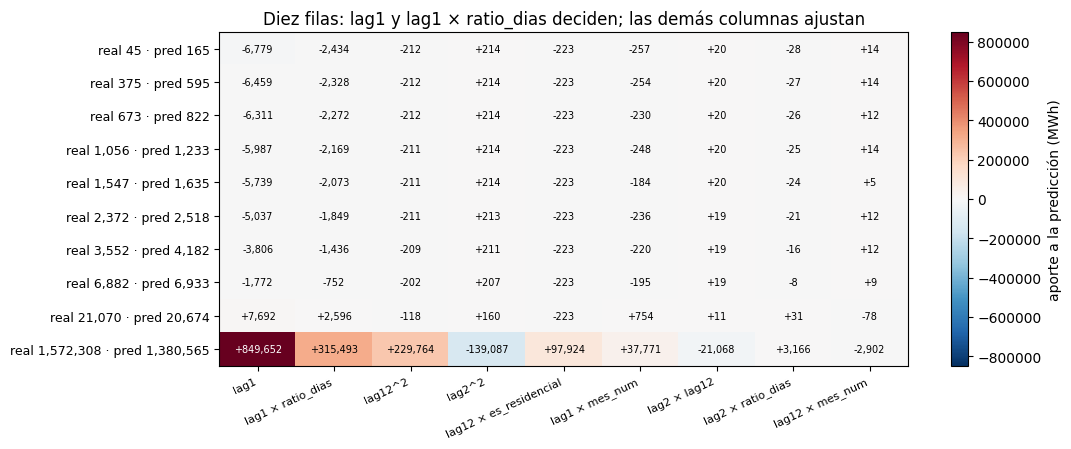

In [32]:
fig, ax = plt.subplots(figsize=(11, 4.6))
im = ax.imshow(aportes.to_numpy(), cmap="RdBu_r", vmin=-lim_ap, vmax=lim_ap, aspect="auto")
ax.set_xticks(range(aportes.shape[1])); ax.set_xticklabels(aportes.columns, rotation=25, ha="right", fontsize=8)
ax.set_yticks(range(len(elegidos))); ax.set_yticklabels([f"real {r:,.0f} · pred {p:,.0f}" for r, p in zip(explicado["real"], explicado["predicho"])], fontsize=9)
for i in range(aportes.shape[0]):
    for j in range(aportes.shape[1]):
        v = aportes.iloc[i, j]; ax.text(j, i, f"{v:+,.0f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > lim_ap / 2 else "black")
plt.colorbar(im, ax=ax, label="aporte a la predicción (MWh)")
ax.set_title("Diez filas: lag1 y lag1 × ratio_dias deciden; las demás columnas ajustan")
plt.tight_layout(); plt.show()

In [33]:
medias = pd.Series(final[-2].mean_, index=nombres(final))
def num(v): return f"{v:,.0f}".replace(",", ".")
def valor_de(fila_id, col):
    """El valor crudo de una columna expandida: la columna, su cuadrado o el producto de dos."""
    if " × " in col:
        a, b = col.split(" × "); va, vb = X_pru.loc[fila_id, a], X_pru.loc[fila_id, b]
        return (None if pd.isna(va) or pd.isna(vb) else va * vb), f"{num(va)} × {vb:.3f}" if b == "ratio_dias" else f"{num(va)} × {num(vb)}"
    if col.endswith("^2"):
        v = X_pru.loc[fila_id, col[:-2]]; return (None if pd.isna(v) else v ** 2), f"{num(v)}²"
    v = X_pru.loc[fila_id, col]; return (None if pd.isna(v) else v), None
for fila_id in aportes.index:
    fila = explicado.loc[fila_id]; ap = aportes.loc[fila_id]
    partes = []
    for col in ap.abs().sort_values(ascending=False).index[:2]:
        valor, texto = valor_de(fila_id, col)
        valor_txt = "con un dato faltante, imputado" if valor is None else (num(valor) if texto is None else f"{texto} = {num(valor)}")
        lado = "por encima" if Z10.loc[fila_id, col] > 0 else "por debajo"
        partes.append(f"{num(ap[col])} por {col} ({valor_txt}, {lado} del promedio de {num(medias[col])})")
    veredicto = "acierto" if abs(fila["error %"]) < 10 else ("se queda corto" if fila["error"] > 0 else "se pasa")
    print(f"{fila['serie']}: predicho {num(fila['predicho'])}, real {num(fila['real'])} MWh ({veredicto}, {fila['error %']:+.1f} %). "
          f"Parte de {num(final[-1].intercept_)}; " + "; ".join(partes) + ".")

APARBONY | GUMAS/AUTOGENERADORES: predicho 165, real 45 MWh (se pasa, -266.7 %). Parte de 9.851; -6.779 por lag1 (52, por debajo del promedio de 9.833); -2.434 por lag1 × ratio_dias (52 × 1.000 = 52, por debajo del promedio de 9.829).
ACARQQ3Y | GUMAS/AUTOGENERADORES: predicho 595, real 375 MWh (se pasa, -58.7 %). Parte de 9.851; -6.459 por lag1 (513, por debajo del promedio de 9.833); -2.328 por lag1 × ratio_dias (513 × 0.935 = 480, por debajo del promedio de 9.829).
SPICPNOY | GUMAS/AUTOGENERADORES: predicho 822, real 673 MWh (se pasa, -22.1 %). Parte de 9.851; -6.311 por lag1 (727, por debajo del promedio de 9.833); -2.272 por lag1 × ratio_dias (727 × 0.968 = 704, por debajo del promedio de 9.829).
AGEABACY | GUMAS/AUTOGENERADORES: predicho 1.233, real 1.056 MWh (se pasa, -16.8 %). Parte de 9.851; -5.987 por lag1 (1.194, por debajo del promedio de 9.833); -2.169 por lag1 × ratio_dias (1.194 × 0.935 = 1.117, por debajo del promedio de 9.829).
MASAMEOY | GUMAS/AUTOGENERADORES: predich

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La estructura se repite: el sesgo (la fila promedio), un aporte grande de <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1</code> que lleva la predicción al tamaño del agente, y el producto con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">ratio_dias</code> que la corrige según el largo del mes. Los errores relativos más grandes siguen estando en los agentes chicos, y el modelo todavía no tiene piso: puede dar valores negativos. Eso queda para un modelo sobre el logaritmo.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La misma predicción, en una aplicación</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Se guardan la recta de la clase 29 y el modelo elegido (grado 2 + Lasso). La app calcula <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">ratio_dias</code> a partir del mes elegido y muestra las dos predicciones lado a lado: al pasar de enero a febrero la recta casi no cambia y Lasso baja.</p></div>

In [34]:
import joblib

joblib.dump(recta, "modelo_demanda_cammesa.joblib")          # la recta de la clase 29 (6 predictoras)
joblib.dump(final, "modelo_demanda_cammesa_31.joblib")       # el elegido: grado 2 + Lasso (7 predictoras)
cargado = joblib.load("modelo_demanda_cammesa_31.joblib")
print("Modelos guardados: modelo_demanda_cammesa.joblib y modelo_demanda_cammesa_31.joblib")
print("Misma predicción tras guardar y cargar:", np.allclose(cargado.predict(X_pru), final.predict(X_pru)))

Modelos guardados: modelo_demanda_cammesa.joblib y modelo_demanda_cammesa_31.joblib
Misma predicción tras guardar y cargar: True


In [35]:
%%writefile app_demanda_cammesa_31.py
# Clase 31 sobre CAMMESA · polinómica + Lasso contra la recta · aplicación Streamlit
# Para abrirla, desde la carpeta del cuaderno:  streamlit run app_demanda_cammesa_31.py
import calendar
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import streamlit as st

st.set_page_config(page_title="Demanda mensual: recta y polinómica", layout="centered")
st.title("¿Cuántos MWh va a demandar este agente?")
st.caption("Recta (clase 29) y polinómica de grado 2 con Lasso (clase 31), sobre demanda-ltimos-aos.csv (CAMMESA).")

@st.cache_resource
def cargar_modelos():
    return joblib.load("modelo_demanda_cammesa.joblib"), joblib.load("modelo_demanda_cammesa_31.joblib")

recta, polinomica = cargar_modelos()
MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre", "octubre", "noviembre", "diciembre"]

st.subheader("Historia del agente")
c1, c2 = st.columns(2)
lag1 = c1.number_input("Demanda del mes anterior (MWh)", 0.0, 1_600_000.0, 50_000.0, step=1000.0)
lag2 = c1.number_input("Demanda de hace dos meses (MWh)", 0.0, 1_600_000.0, 48_000.0, step=1000.0)
tiene_lag12 = c1.checkbox("Conozco la demanda de hace un año", value=True)
lag12 = c1.number_input("Demanda del mismo mes del año pasado (MWh)", 0.0, 1_600_000.0, 52_000.0, step=1000.0, disabled=not tiene_lag12)
anio = c2.number_input("Año", 2017, 2030, 2020)
mes = MESES.index(c2.selectbox("Mes a predecir", MESES, index=1)) + 1
tipo = c2.radio("Tipo de agente", ["Distribuidor · residencial", "Distribuidor · no residencial", "Gran usuario"])

anio_ant, mes_ant = (anio - 1, 12) if mes == 1 else (anio, mes - 1)
ratio_dias = calendar.monthrange(anio, mes)[1] / calendar.monthrange(anio_ant, mes_ant)[1]
fila = pd.DataFrame([{"lag1": lag1, "lag2": lag2, "lag12": lag12 if tiene_lag12 else np.nan, "mes_num": mes,
                      "es_gran_usuario": int(tipo == "Gran usuario"), "es_residencial": int(tipo == "Distribuidor · residencial"),
                      "ratio_dias": ratio_dias}])
est_recta = float(recta.predict(fila.drop(columns="ratio_dias"))[0])
est_poli = float(polinomica.predict(fila)[0])

st.subheader("Predicción")
m1, m2, m3 = st.columns(3)
m1.metric("Recta (clase 29)", f"{est_recta:,.0f} MWh")
m2.metric("Polinómica + Lasso", f"{est_poli:,.0f} MWh", delta=f"{est_poli - est_recta:+,.0f} vs. recta", delta_color="off")
m3.metric("Mes anterior × días", f"{lag1 * ratio_dias:,.0f} MWh")
st.write(f"ratio_dias = {ratio_dias:.3f} (días de {MESES[mes - 1]} / días del mes anterior). "
         "Pasá de enero a febrero y a marzo: la polinómica reacciona al largo del mes (multiplica); la recta suma casi lo mismo cada mes.")

meses = np.arange(1, 13)
filas = []
for m in meses:
    aa, ma = (anio - 1, 12) if m == 1 else (anio, m - 1)
    filas.append({**fila.iloc[0].to_dict(), "mes_num": m, "ratio_dias": calendar.monthrange(anio, m)[1] / calendar.monthrange(aa, ma)[1]})
curva = pd.DataFrame(filas)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(meses, recta.predict(curva.drop(columns="ratio_dias")), marker="o", color="#6b7280", label="recta (clase 29)")
ax.plot(meses, polinomica.predict(curva), marker="o", color="#c0392b", label="polinómica + Lasso")
ax.axhline(lag1, color="black", lw=0.6, ls=":", label="mes anterior")
ax.set_xticks(meses); ax.set_xticklabels([m[:3] for m in MESES]); ax.set_ylabel("MWh predichos"); ax.legend(fontsize=8)
ax.set_title("La misma historia, predicha para cada mes del año")
st.pyplot(fig)

with st.expander("Ver la fila que recibe el modelo"):
    st.dataframe(fila)

Writing app_demanda_cammesa_31.py


<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Cómo abrirla</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">streamlit</code> instalado en <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">aa2026</code>: desde una terminal en la carpeta del cuaderno, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">streamlit run app_demanda_cammesa_31.py</code>.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Desde el cuaderno:</b> la celda siguiente la lanza en modo sin consola; entrar a <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">http://localhost:8501</code> y, para cortarla, interrumpir el kernel (■).</p></div>

In [36]:
import sys
print("Abrir http://localhost:8501 en el navegador. Para cortarla: interrumpir el kernel (■).")
!"{sys.executable}" -m streamlit run app_demanda_cammesa_31.py --server.headless true

Abrir http://localhost:8501 en el navegador. Para cortarla: interrumpir el kernel (■).
^C


<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">8 · Qué quedó</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Lo que la recta no captó se encontró mirando los datos:</b> la demanda mensual depende del largo del mes, y la corrección es un producto, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1 × ratio_dias</code>. Una recta no puede multiplicar; la polinómica de grado 2 tiene ese término.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Sin freno, la polinómica no sirve con estos datos.</b> Con rezagos casi iguales, el grado 2 sin regularizar usa pesos enormes que se cancelan y sobreajusta; desde el grado 3 los cubos de valores de un millón de MWh extrapolan sin control. La curva de validación, sin freno, elige el grado 1.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Con freno, el grado 2 gana.</b> Ridge achica los pares que se cancelaban; Lasso además elige columnas y se queda con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag1</code> y su producto con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">ratio_dias</code>. Los α se eligieron con validación cruzada temporal y en una escala muy distinta a la del gimnasio. Escalar antes de frenar no es opcional.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Donde el resultado difiere de la clase:</b> el grado alto con Ridge no se rescata (colas demasiado largas) y la detención temprana se hizo con gradiente por lotes porque el estocástico diverge; funciona sobre la validación, pero no alcanza para que el grado 3 sirva en prueba. Son resultados, no errores.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Qué sigue:</b> modelar el logaritmo de la demanda (el error de los agentes gigantes domina todo), y comparar siempre contra la referencia «mes anterior × ratio_dias», que sin aprender nada ya es muy difícil de ganar.</p></div>